# Atención y arquitectura Transformer
## Del producto punto al bloque Transformer: teoría, implementación y experimentación

**Asignatura:** Análisis, Procesamiento y Aplicación de Inteligencia Artificial  
**Tema anterior:** Embeddings, representaciones semánticas y similitud vectorial  
**Tema siguiente:** Fine-tuning y evaluación de modelos de lenguaje

---

## Objetivo general

Comprender e implementar de forma progresiva el mecanismo de atención y la arquitectura Transformer, analizando cómo se procesan las secuencias, cómo se establecen relaciones entre tokens y cómo se generan representaciones contextuales.

## Resultados de aprendizaje

Al finalizar este notebook usted podrá:

1. Explicar por qué una representación estática (un vector fijo por palabra) es insuficiente y qué problema resuelve la atención.
2. Calcular a mano y con NumPy las puntuaciones de atención, la función Softmax y la representación contextualizada de un token.
3. Construir **Self-Attention** con las matrices Query, Key y Value, y justificar el factor $1/\sqrt{d_k}$.
4. Interpretar mapas de calor de atención, reconociendo qué muestran y qué **no** muestran.
5. Explicar y programar **Multi-Head Attention**, la **codificación posicional** y las **máscaras** de atención.
6. Describir la estructura de un bloque Transformer y la diferencia entre modelos *encoder-only*, *decoder-only* y *encoder-decoder*.
7. Implementar un bloque Transformer en PyTorch, controlando las dimensiones de cada tensor.
8. Usar un Transformer preentrenado y comparar sus representaciones contextualizadas con embeddings estáticos.

## Herramientas

Python, NumPy, Matplotlib, PyTorch, Hugging Face Transformers y, de forma opcional, Sentence Transformers (para contrastar con el tema anterior).

## Estructura y ruta de construcción

El notebook se construye de manera **incremental**: primero atención con NumPy, luego Self-Attention, después Multi-Head Attention y, solo al final, el bloque Transformer en PyTorch. Así cada componente tiene sentido antes de integrarse.

| Bloque | Secciones | Contenido | Herramienta principal |
|---|---|---|---|
| 1. Fundamentos | 1 a 3 | Secuencias, tokens, embeddings y la necesidad de atención | NumPy |
| 2. Matemáticas de la atención | 4 a 6 | Producto punto, Softmax, Q/K/V y visualización | NumPy, Matplotlib |
| 3. Arquitectura | 7 a 9 | Multi-Head, codificación posicional y bloque Transformer | NumPy, Matplotlib |
| 4. Implementación | 10 y 11 | Bloque Transformer en PyTorch, máscaras y generación | PyTorch |
| 5. Experimentación | 12 a 15 | Modelo preentrenado, comparación, actividad y cierre | Hugging Face |

La **sección 5** es el punto de mayor profundidad matemática y la **sección 10** es el punto de integración de programación.

## Convenciones de notación

| Símbolo | Significado | Ejemplo en este notebook |
|---|---|---|
| $n$ (o `seq_len`) | Número de tokens de la secuencia | 5 para "el banco aprobó el crédito" |
| $d_{model}$ | Dimensión del embedding (ancho del modelo) | 6 en NumPy, 16 en PyTorch, 768 en BERT |
| $d_k$, $d_v$ | Dimensión de claves/consultas y de valores | 4 |
| $h$ | Número de cabezas de atención | 2 o 4 |
| $d_{head}$ | Dimensión por cabeza, $d_{model}/h$ | 3 o 4 |
| $b$ (o `batch`) | Número de secuencias procesadas a la vez | 2 |

> **Cómo leer este notebook.** Las celdas marcadas como **Idea clave** resumen un concepto; **Verificación** comprueba con código algo que se afirma en el texto; **Ejercicio** requiere que usted participe; **Advertencia** señala una confusión frecuente. Ejecute las celdas en orden: las secciones posteriores reutilizan variables y funciones de las anteriores.

### Preparación del entorno

Las secciones 1 a 9 solo necesitan NumPy, pandas y Matplotlib. PyTorch se utiliza desde la sección 10 y Hugging Face Transformers en la sección 12. Si falta alguna biblioteca, ejecute en una celda: `%pip install numpy pandas matplotlib torch transformers`.

La celda siguiente fija la semilla aleatoria (para que los resultados sean reproducibles), define el estilo de los gráficos y las dos funciones auxiliares que se usarán durante todo el notebook: `softmax` y `coseno`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)
pd.set_option("display.float_format", "{:.3f}".format)

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10,
    "axes.spines.top": False, "axes.spines.right": False,
})
AZUL, NARANJA = "#2563b8", "#c8621b"      # dos colores con buen contraste entre sí


def softmax(z, axis=-1):
    """Softmax numéricamente estable: resta el máximo antes de exponenciar."""
    z = z - np.max(z, axis=axis, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=axis, keepdims=True)


def coseno(a, b):
    """Similitud coseno entre dos vectores (ver el notebook anterior)."""
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b)))


def graficar_atencion(pesos, tokens_q, tokens_k=None, titulo="", ax=None,
                      anotar=True, cmap="Blues", vmin=0.0, vmax=1.0):
    """Mapa de calor de una matriz de atención (filas = consultas, columnas = claves)."""
    tokens_k = tokens_q if tokens_k is None else tokens_k
    creado = ax is None
    if creado:
        _, ax = plt.subplots(figsize=(1.2 + 0.7 * len(tokens_k), 0.9 + 0.55 * len(tokens_q)))
    im = ax.imshow(pesos, cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_xticks(range(len(tokens_k)), tokens_k, rotation=45, ha="right")
    ax.set_yticks(range(len(tokens_q)), tokens_q)
    ax.set_xlabel("Clave (token que se consulta)")
    ax.set_ylabel("Consulta (token que atiende)")
    ax.set_title(titulo)
    if anotar:
        for i in range(pesos.shape[0]):
            for j in range(pesos.shape[1]):
                v = pesos[i, j]
                oscuro = (v - vmin) > 0.55 * (vmax - vmin)
                ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                        color="white" if oscuro else "#1a1a1a")
    if creado:
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
        plt.tight_layout()
        plt.show()
    return im

rng = np.random.default_rng(42)
print("Entorno listo.")

Entorno listo.


# 1. Introducción y conexión con embeddings

**Objetivo:** recuperar lo aprendido sobre embeddings y establecer el problema que resuelve la atención.

## 1.1 Presentación del tema

En el tema anterior vimos que un **embedding** convierte una unidad de texto en un vector $\mathbf{v}\in\mathbb{R}^{d}$ y que la cercanía entre vectores puede reflejar relaciones semánticas. Pero quedó una pregunta abierta: ¿qué ocurre cuando **la misma palabra significa cosas distintas** según la oración?

Los modelos de lenguaje actuales (BERT, GPT, T5, Claude, entre otros) están construidos sobre la arquitectura **Transformer**, cuyo ingrediente central es el **mecanismo de atención**. Este notebook explica ese mecanismo desde cero, con matemáticas pequeñas que se pueden calcular a mano, y lo escala hasta un bloque Transformer funcional.

## 1.2 ¿Qué es una secuencia y cómo se representa numéricamente?

Una **secuencia** es una lista **ordenada** de elementos (aquí, tokens). Un computador no opera sobre palabras sino sobre números, así que cada token se reemplaza por un vector y la secuencia completa se convierte en una **matriz**:

$$
X\in\mathbb{R}^{n\times d_{model}}
$$

- Cada **fila** es un token (hay $n$ filas: la longitud de la secuencia).
- Cada **columna** es una dimensión del embedding (hay $d_{model}$ columnas: el ancho del vector).

## 1.3 Repaso: tokens, embeddings y dimensiones vectoriales

| Concepto | Qué es | Ejemplo |
|---|---|---|
| Token | Unidad en que se divide el texto (palabra o fragmento de palabra) | `"banco"` |
| Token ID | Número entero que identifica al token en el vocabulario | `2` |
| Embedding | Vector denso asociado a un token | `[0.6, 0.6, 0.0, ...]` |
| Dimensión $d_{model}$ | Longitud del vector de cada token | 6, 16, 768, ... |

## 1.4 Representación estática frente a contextual

| | **Estática** | **Contextual** |
|---|---|---|
| Vector por palabra | Uno solo, fijo | Cambia según la oración |
| Ejemplo | Una tabla de búsqueda (*lookup*) | La salida de un Transformer |
| "banco" en dos oraciones | Mismo vector en ambas | Vectores distintos |
| Ambigüedad | No la resuelve | Puede resolverla con ayuda de las palabras vecinas |

Una **representación estática** asigna a cada palabra siempre el mismo vector, sin importar qué palabras la rodean. Una **representación contextual** produce el vector de cada token *después* de considerar al resto de la secuencia. El mecanismo que permite esa consideración es la atención.

## 1.5 El problema de interpretar palabras sin su contexto

Observe estas dos oraciones:

- *El banco aprobó el crédito.* (institución financiera)
- *El banco del parque es cómodo.* (asiento)

La palabra "banco" es la misma, pero su significado depende de "crédito" en un caso y de "parque" y "cómodo" en el otro. Un sistema que represente "banco" con un único vector no puede distinguirlas.

### Léxico de juguete para practicar

Para poder **calcular y entender** cada paso, usaremos un pequeño léxico con vectores diseñados a mano. Cada dimensión tiene un nombre legible. 

> **Advertencia.** En un modelo real las dimensiones **se aprenden** durante el entrenamiento y, por lo general, **no tienen una interpretación humana individual**. Aquí las nombramos solo por fines didácticos.

In [2]:
caracteristicas = ["finanzas", "mobiliario", "evento", "ubicación", "función gramatical", "institución"]

lexico = {
    "el":      [0.0, 0.0, 0.0, 0.0, 1.0, 0.0],
    "del":     [0.0, 0.0, 0.0, 0.5, 1.0, 0.0],
    "banco":   [0.6, 0.6, 0.0, 0.3, 0.0, 0.5],   # ambiguo: algo de finanzas y algo de mobiliario
    "aprobó":  [0.3, 0.0, 1.0, 0.0, 0.0, 0.3],
    "crédito": [1.0, 0.0, 0.0, 0.0, 0.0, 0.3],
    "es":      [0.0, 0.0, 0.6, 0.0, 0.3, 0.0],
    "parque":  [0.0, 0.5, 0.0, 1.0, 0.0, 0.0],
    "cómodo":  [0.0, 1.0, 0.0, 0.0, 0.0, 0.0],
}

pd.DataFrame(lexico, index=caracteristicas).T

,finanzas,mobiliario,evento,ubicación,función gramatical,institución
el,0.000,0.000,0.000,0.000,1.000,0.000
del,0.000,0.000,0.000,0.500,1.000,0.000
banco,0.600,0.600,0.000,0.300,0.000,0.500
aprobó,0.300,0.000,1.000,0.000,0.000,0.300
crédito,1.000,0.000,0.000,0.000,0.000,0.300
es,0.000,0.000,0.600,0.000,0.300,0.000
parque,0.000,0.500,0.000,1.000,0.000,0.000
cómodo,0.000,1.000,0.000,0.000,0.000,0.000


### Práctica 1.  Cada token tiene inicialmente un vector

Representemos las dos oraciones buscando cada token en el léxico (una **tabla de búsqueda**, es decir, una representación estática) y comprobemos qué ocurre con "banco".

In [3]:
oracion_1 = "El banco aprobó el crédito"
oracion_2 = "El banco del parque es cómodo"

tokens_1 = oracion_1.lower().split()
tokens_2 = oracion_2.lower().split()

# Representación estática: buscar cada token en el léxico
vectores_1 = np.array([lexico[t] for t in tokens_1])
vectores_2 = np.array([lexico[t] for t in tokens_2])

print("Oración 1:", tokens_1)
display(pd.DataFrame(vectores_1, index=tokens_1, columns=caracteristicas))

banco_en_1 = vectores_1[tokens_1.index("banco")]
banco_en_2 = vectores_2[tokens_2.index("banco")]
print("Vector de 'banco' en la oración 1:", banco_en_1)
print("Vector de 'banco' en la oración 2:", banco_en_2)
print("¿Son idénticos?", np.array_equal(banco_en_1, banco_en_2))

Oración 1: ['el', 'banco', 'aprobó', 'el', 'crédito']


,finanzas,mobiliario,evento,ubicación,función gramatical,institución
el,0.000,0.000,0.000,0.000,1.000,0.000
banco,0.600,0.600,0.000,0.300,0.000,0.500
aprobó,0.300,0.000,1.000,0.000,0.000,0.300
el,0.000,0.000,0.000,0.000,1.000,0.000
crédito,1.000,0.000,0.000,0.000,0.000,0.300


Vector de 'banco' en la oración 1: [0.6 0.6 0.  0.3 0.  0.5]
Vector de 'banco' en la oración 2: [0.6 0.6 0.  0.3 0.  0.5]
¿Son idénticos? True


> **Idea clave.** Con una representación estática, "banco" recibe **exactamente el mismo vector** en las dos oraciones. El sistema no tiene forma de saber en cuál sentido se está usando. Necesitamos un mecanismo que, para cada token, **mire al resto de la secuencia y ajuste su representación**. Ese mecanismo es la atención.

# 2. Preparación de una secuencia para el procesamiento

**Objetivo:** comprender qué recibe realmente un Transformer como entrada.

El camino que sigue un texto antes de llegar a la primera capa del modelo es:

$$
\text{texto}\;\longrightarrow\;\text{tokens}\;\longrightarrow\;\text{Token IDs}\;\longrightarrow\;\text{embeddings (matriz }X\text{)}
$$

| Sección | Qué ocurre | Resultado |
|---|---|---|
| 2.1 Tokenización | Se divide la oración en unidades | `["el", "banco", "aprobó", ...]` |
| 2.2 Token IDs | Cada token se reemplaza por un entero | `[1, 2, 3, ...]` |
| 2.3 Vocabulario y embeddings | Una **matriz de embeddings** $E$ guarda un vector por cada token del vocabulario | $E\in\mathbb{R}^{\lvert V\rvert\times d_{model}}$ |
| 2.4 Dimensionalidad | Cada vector tiene $d_{model}$ componentes | 6 en este ejemplo |
| 2.5 Secuencia como matriz | Se seleccionan las filas de $E$ correspondientes a los IDs | $X\in\mathbb{R}^{n\times d_{model}}$ |

Construyamos cada paso con una tokenización **simplificada** (separar por espacios).

In [4]:
def tokenizar(oracion):
    """Tokenización simplificada: minúsculas, sin signos de puntuación, separada por espacios."""
    for signo in ".,;:¿?¡!":
        oracion = oracion.replace(signo, "")
    return oracion.lower().split()

corpus = [oracion_1, oracion_2]

# Vocabulario: el ID 0 se reserva para el relleno ("padding"), que usaremos más adelante
vocabulario = ["<pad>"] + sorted({t for o in corpus for t in tokenizar(o)})
token_a_id = {t: i for i, t in enumerate(vocabulario)}
id_a_token = {i: t for t, i in token_a_id.items()}

print("Vocabulario:", token_a_id)

ids_1 = [token_a_id[t] for t in tokenizar(oracion_1)]
ids_2 = [token_a_id[t] for t in tokenizar(oracion_2)]
print("\nOración 1:", tokenizar(oracion_1), "->", ids_1)
print("Oración 2:", tokenizar(oracion_2), "->", ids_2)

Vocabulario: {'<pad>': 0, 'aprobó': 1, 'banco': 2, 'crédito': 3, 'cómodo': 4, 'del': 5, 'el': 6, 'es': 7, 'parque': 8}

Oración 1: ['el', 'banco', 'aprobó', 'el', 'crédito'] -> [6, 2, 1, 6, 3]
Oración 2: ['el', 'banco', 'del', 'parque', 'es', 'cómodo'] -> [6, 2, 5, 8, 7, 4]


### Matriz de embeddings $E$ y matriz de la secuencia $X$

La matriz $E$ tiene **una fila por cada token del vocabulario**. Obtener los embeddings de una oración es simplemente **seleccionar filas** de $E$ usando los IDs:

$$
X = E[\text{ids}]
$$

In [5]:
d_model = len(caracteristicas)          # dimensión del embedding (6)

# Matriz de embeddings: (tamaño del vocabulario) x (d_model)
E = np.zeros((len(vocabulario), d_model))
for token, i in token_a_id.items():
    if token != "<pad>":
        E[i] = lexico[token]

print("Forma de E:", E.shape, " -> (tamaño del vocabulario, d_model)")
display(pd.DataFrame(E, index=vocabulario, columns=caracteristicas))

# Secuencia -> matriz: seleccionar las filas de E correspondientes a los IDs
X1 = E[ids_1]
X2 = E[ids_2]
print("Forma de X1:", X1.shape, " -> (n = 5 tokens, d_model = 6)")
print("Forma de X2:", X2.shape, " -> (n = 6 tokens, d_model = 6)")
display(pd.DataFrame(X1, index=tokenizar(oracion_1), columns=caracteristicas))

Forma de E: (9, 6)  -> (tamaño del vocabulario, d_model)


,finanzas,mobiliario,evento,ubicación,función gramatical,institución
<pad>,0.000,0.000,0.000,0.000,0.000,0.000
aprobó,0.300,0.000,1.000,0.000,0.000,0.300
banco,0.600,0.600,0.000,0.300,0.000,0.500
crédito,1.000,0.000,0.000,0.000,0.000,0.300
cómodo,0.000,1.000,0.000,0.000,0.000,0.000
del,0.000,0.000,0.000,0.500,1.000,0.000
el,0.000,0.000,0.000,0.000,1.000,0.000
es,0.000,0.000,0.600,0.000,0.300,0.000
parque,0.000,0.500,0.000,1.000,0.000,0.000


Forma de X1: (5, 6)  -> (n = 5 tokens, d_model = 6)
Forma de X2: (6, 6)  -> (n = 6 tokens, d_model = 6)


,finanzas,mobiliario,evento,ubicación,función gramatical,institución
el,0.000,0.000,0.000,0.000,1.000,0.000
banco,0.600,0.600,0.000,0.300,0.000,0.500
aprobó,0.300,0.000,1.000,0.000,0.000,0.300
el,0.000,0.000,0.000,0.000,1.000,0.000
crédito,1.000,0.000,0.000,0.000,0.000,0.300


> **Idea clave: no confundir $n$ con $d_{model}$.**
> - $n$ (`seq_len`) es la **cantidad de tokens** de la secuencia. **Cambia** de una oración a otra (5 en la primera, 6 en la segunda).
> - $d_{model}$ es la **dimensión de cada embedding**. Es una **constante del modelo** (6 aquí; 768 en BERT-base).
>
> Una oración más larga agrega *filas* a $X$, no *columnas*. Esto es importante: la atención compara tokens entre sí, de modo que su costo crece con $n$, mientras que $d_{model}$ fija el tamaño de la representación de cada token.

### ¿Qué pasa con una palabra que no está en el vocabulario?

Una tokenización por palabras completas tiene un problema práctico: cualquier palabra nueva queda fuera. Veámoslo.

In [6]:
try:
    token_a_id["harina"]
except KeyError as error:
    print("KeyError: la palabra", error, "no existe en el vocabulario.")

KeyError: la palabra 'harina' no existe en el vocabulario.


Los modelos reales evitan este problema con tokenizadores de **subpalabras** (BPE, WordPiece, SentencePiece): una palabra desconocida se divide en fragmentos conocidos (por ejemplo, `"harinas"` podría dividirse en `"harina"` + `"s"`). Veremos un tokenizador real en la sección 12. En este notebook mantenemos la versión simplificada para concentrarnos en la atención.

# 3. El problema de la atención

**Objetivo:** comprender por qué un modelo necesita identificar relaciones entre los elementos de una secuencia.

## 3.1 Limitaciones de procesar tokens de forma independiente

Si cada token se procesa **solo**, con su propio vector, el modelo no puede usar la información que aportan los demás. Ya lo vimos con "banco": el vector de entrada no cambia aunque cambie la oración.

## 3.2 Dependencias entre palabras

Interpretar una oración exige relacionar palabras que pueden estar **lejos** una de otra:

- Un pronombre se refiere a un sustantivo anterior (*él*, *lo*).
- Un verbo concuerda con su sujeto.
- Un adjetivo modifica a un sustantivo.
- Una negación cambia el sentido de una frase completa.

## 3.3 Contexto local y contexto global

- **Contexto local:** las palabras inmediatamente vecinas (una ventana de pocos tokens).
- **Contexto global:** **cualquier** otra palabra de la secuencia, sin importar la distancia.

Los primeros modelos de secuencias (redes recurrentes) procesaban un token a la vez y la información de los tokens lejanos tenía que "viajar" paso a paso. La atención, en cambio, permite que **cada token consulte directamente a todos los demás** en una sola operación.

## 3.4 ¿Qué significa "prestar atención" a un token?

Significa **asignarle un peso**: al construir la nueva representación de un token, se combinan los vectores de los demás tokens, dando **más peso** a los que son más relevantes para él y **menos peso** a los irrelevantes.

## 3.5 Introducción intuitiva al mecanismo de atención

Una analogía útil es una **búsqueda en una biblioteca**:

| Elemento de la analogía | Equivalente en atención |
|---|---|
| Lo que usted busca ("libros sobre ríos") | **Query** (consulta) |
| La etiqueta de cada libro en el catálogo | **Key** (clave) |
| El contenido del libro | **Value** (valor) |
| Qué tan bien coincide la consulta con cada etiqueta | **Puntuación de atención** |
| Cuánto del contenido de cada libro se toma (suma 100 %) | **Peso de atención** (Softmax) |

El resultado final es una **mezcla ponderada** del contenido de los libros que más coinciden con lo buscado. En las secciones siguientes convertiremos esta intuición en cálculo exacto.

## Ejercicio 3. Relaciones en una oración

Considere la oración:

> «El estudiante entregó el proyecto al profesor porque él lo solicitó».

Primero la tokenizamos y medimos qué palabras caen dentro de una **ventana local** alrededor de "él".

In [7]:
frase = "El estudiante entregó el proyecto al profesor porque él lo solicitó"
tokens_f = tokenizar(frase)

consulta_f = tokens_f.index("él")
ventana = 2     # contexto local: hasta 2 tokens a cada lado

tabla = pd.DataFrame({
    "token": tokens_f,
    "posición": range(len(tokens_f)),
    "distancia a 'él'": [abs(j - consulta_f) for j in range(len(tokens_f))],
})
tabla["¿en la ventana local?"] = tabla["distancia a 'él'"] <= ventana
tabla

,token,posición,distancia a 'él',¿en la ventana local?
0,el,0,8,False
1,estudiante,1,7,False
2,entregó,2,6,False
3,el,3,5,False
4,proyecto,4,4,False
5,al,5,3,False
6,profesor,6,2,True
7,porque,7,1,True
8,él,8,0,True
9,lo,9,1,True


**Preguntas para discutir (anótelas antes de continuar):**

1. ¿A quién se refiere "él": al estudiante o al profesor? ¿Qué información usó para decidirlo?
2. ¿A qué se refiere "lo"?
3. ¿Quedó "estudiante" dentro de la ventana local de "él"? ¿Y "proyecto" respecto de "lo"? ¿Qué implica esto para un modelo que solo mire a sus vecinos inmediatos?
4. Si tuviera que repartir 100 puntos de atención para el token "lo" entre las demás palabras, ¿cómo los repartiría?

> **Discusión orientativa.** "él" es ambiguo: gramaticalmente podría ser el estudiante o el profesor. La lectura más natural es que el profesor solicitó el proyecto, pero esa conclusión se apoya en conocimiento del mundo (quién suele solicitar un trabajo), no solo en la gramática. "lo" se refiere a "proyecto", que está **fuera** de su ventana local de dos tokens. Un modelo debe poder relacionar tokens a distancia y asignar pesos distintos a cada candidato. Esa es precisamente la función de la atención.

# 4. Fundamentos matemáticos del mecanismo de atención

**Objetivo:** comprender el funcionamiento matemático de la atención **antes** de utilizar PyTorch.

La atención se reduce a cuatro operaciones encadenadas:

$$
\underbrace{\text{producto punto}}_{\text{4.2}}
\;\rightarrow\;
\underbrace{\text{puntuaciones}}_{\text{4.3}}
\;\rightarrow\;
\underbrace{\text{Softmax}}_{\text{4.4}}
\;\rightarrow\;
\underbrace{\text{pesos}}_{\text{4.5}}
\;\rightarrow\;
\underbrace{\text{suma ponderada}}_{\text{4.6}}
$$

## 4.1 Vectores y matrices involucrados

En esta sección trabajamos con **tres tokens**, cada uno representado por un vector de 3 dimensiones. Los números son inventados para que los cálculos se puedan seguir a mano. Piense en las dimensiones como "finanzas", "mobiliario" y "acción": "banco" es **ambiguo**, con el mismo valor en las dos primeras.

| Token | Vector $\mathbf{x}$ |
|---|---|
| banco | $[1.5,\;1.5,\;0.0]$ |
| crédito | $[2.0,\;0.2,\;0.1]$ |
| aprobó | $[0.5,\;0.0,\;2.0]$ |

Apilados forman una matriz $T\in\mathbb{R}^{3\times 3}$ (3 tokens, 3 dimensiones). Elegiremos **"banco" como consulta**: queremos saber a cuáles de los tres tokens (incluido él mismo) debe prestar atención para construir su nueva representación.

In [8]:
nombres = ["banco", "crédito", "aprobó"]
T = np.array([[1.5, 1.5, 0.0],      # banco
              [2.0, 0.2, 0.1],      # crédito
              [0.5, 0.0, 2.0]])     # aprobó

print("Forma de T:", T.shape, "-> (3 tokens, 3 dimensiones)")
display(pd.DataFrame(T, index=nombres, columns=["dim 1", "dim 2", "dim 3"]))

# Paso 1-2. Elegir la consulta: el token "banco"
q = T[0]
print("Consulta (banco):", q)

Forma de T: (3, 3) -> (3 tokens, 3 dimensiones)


,dim 1,dim 2,dim 3
banco,1.500,1.500,0.000
crédito,2.000,0.200,0.100
aprobó,0.500,0.000,2.000


Consulta (banco): [1.5 1.5 0. ]


## 4.2 Producto punto entre vectores

El **producto punto** de dos vectores multiplica componente a componente y suma:

$$
\mathbf{a}\cdot\mathbf{b}=\sum_{i=1}^{d}a_i b_i=\lVert\mathbf{a}\rVert\,\lVert\mathbf{b}\rVert\cos\theta
$$

Es **grande y positivo** cuando los vectores apuntan en direcciones parecidas, cercano a **cero** cuando son perpendiculares y **negativo** cuando apuntan en sentidos opuestos. Por eso funciona como una **medida de afinidad**: recordemos del tema anterior que el coseno compara orientaciones; el producto punto añade la magnitud.

## 4.3 Similitud y puntuaciones de atención

La **puntuación de atención** entre la consulta $\mathbf{q}$ y cada token $\mathbf{x}_j$ es simplemente su producto punto:

$$
s_j=\mathbf{q}\cdot\mathbf{x}_j
$$

Calculémoslo paso a paso para cada token, mostrando la cuenta completa.

In [63]:
# Paso 3. Producto punto de la consulta con cada token, mostrando cada multiplicación
puntuaciones = []
for nombre, x in zip(nombres, T):
    productos = q * x
    s = productos.sum()
    puntuaciones.append(s)
    detalle = " + ".join(f"({a:.1f}x{b:.1f})" for a, b in zip(q, x))
    print(f"banco . {nombre:<8} = {detalle} = {s:.2f}")

# Paso 4. Puntuaciones de atención (vector con una puntuación por token)
puntuaciones = np.array(puntuaciones)
print("\nPuntuaciones:", puntuaciones)

# Verificación: hacerlo de una sola vez con una multiplicación matriz-vector
print("Con T @ q   :", T @ q)

banco . banco    = (1.5x1.5) + (1.5x1.5) + (0.0x0.0) = 4.50
banco . crédito  = (1.5x2.0) + (1.5x0.2) + (0.0x0.1) = 3.30
banco . aprobó   = (1.5x0.5) + (1.5x0.0) + (0.0x2.0) = 0.75

Puntuaciones: [4.5  3.3  0.75]
Con T @ q   : [4.5  3.3  0.75]


**Lectura.** "banco" tiene afinidad **alta** consigo mismo (4.5) y con "crédito" (3.3), y **baja** con "aprobó" (0.75). Pero las puntuaciones todavía tienen dos problemas: no suman nada en particular y pueden ser negativas o arbitrariamente grandes. Para usarlas como **porcentajes de mezcla** necesitamos convertirlas en números positivos que sumen 1.

## 4.4 La función Softmax

$$
\operatorname{softmax}(\mathbf{s})_j=\frac{e^{s_j}}{\sum_{k=1}^{n}e^{s_k}}
$$

Propiedades:

1. Todos los resultados son **positivos** (la exponencial nunca es cero ni negativa).
2. Los resultados **suman 1**, de modo que se pueden leer como una distribución de reparto.
3. **Conserva el orden**: la puntuación mayor recibe el peso mayor.
4. **Exagera las diferencias**: una puntuación un poco más alta recibe bastante más peso.

Calculémosla por pasos.

In [10]:
# Paso 5a. Exponencial de cada puntuación
exponenciales = np.exp(puntuaciones)
print("exp(puntuaciones):", exponenciales)

# Paso 5b. Dividir entre la suma de las exponenciales (normalizar)
suma = exponenciales.sum()
pesos = exponenciales / suma
print("suma de exponenciales:", round(suma, 3))
print("pesos de atención    :", pesos)
print("suma de los pesos    :", pesos.sum())

# Verificación con la función softmax definida al inicio
print("¿Coincide con softmax()?", np.allclose(pesos, softmax(puntuaciones)))

exp(puntuaciones): [90.017 27.113  2.117]
suma de exponenciales: 119.247
pesos de atención    : [0.755 0.227 0.018]
suma de los pesos    : 1.0
¿Coincide con softmax()? True


### Por qué `softmax()` resta el máximo

Con puntuaciones grandes, $e^{s}$ se desborda. La solución es restar el máximo antes de exponenciar: el resultado es **matemáticamente idéntico**, porque el factor $e^{-\max(s)}$ aparece en el numerador y en el denominador y se cancela.

In [11]:
grandes = np.array([1000.0, 999.0, 990.0])

with np.errstate(over="ignore", invalid="ignore"):
    ingenuo = np.exp(grandes) / np.exp(grandes).sum()
print("Softmax ingenuo  :", ingenuo, "  (inf/inf = nan: desbordamiento)")
print("Softmax estable  :", softmax(grandes))

Softmax ingenuo  : [nan nan nan]   (inf/inf = nan: desbordamiento)
Softmax estable  : [0.731 0.269 0.   ]


## 4.5 Pesos de atención

Los números obtenidos son los **pesos de atención**: para la consulta "banco", el 75 % de la mezcla proviene de sí mismo, el 23 % de "crédito" y menos del 2 % de "aprobó". Los pesos de una consulta siempre suman 1.

## 4.6 Construcción de una representación contextualizada

La nueva representación de "banco" es la **suma ponderada** de los vectores de todos los tokens, usando los pesos como coeficientes:

$$
\mathbf{c}=\sum_{j=1}^{n}\alpha_j\,\mathbf{x}_j=\alpha_1\mathbf{x}_1+\alpha_2\mathbf{x}_2+\alpha_3\mathbf{x}_3
$$

In [12]:
# Paso 6. Multiplicar cada peso por su vector correspondiente
for nombre, w, x in zip(nombres, pesos, T):
    print(f"{w:.3f} x {nombre:<8} {x}  ->  {w * x}")

# Paso 7. Sumar todo: el vector contextualizado
contexto = (pesos[:, None] * T).sum(axis=0)
print("\nVector contextualizado de 'banco':", contexto)
print("Vector original de 'banco'        :", q)
print("Con pesos @ T (forma matricial)   :", pesos @ T)

0.755 x banco    [1.5 1.5 0. ]  ->  [1.132 1.132 0.   ]
0.227 x crédito  [2.  0.2 0.1]  ->  [0.455 0.045 0.023]
0.018 x aprobó   [0.5 0.  2. ]  ->  [0.009 0.    0.036]

Vector contextualizado de 'banco': [1.596 1.178 0.058]
Vector original de 'banco'        : [1.5 1.5 0. ]
Con pesos @ T (forma matricial)   : [1.596 1.178 0.058]


### El mismo "banco" en otro contexto

Repitamos el cálculo con el mismo vector de "banco", pero rodeado de palabras del sentido de asiento: "cómodo" y "es". Si la atención depende del contexto, el desplazamiento debe ir en otra dirección.

In [13]:
nombres_2 = ["banco", "cómodo", "es"]
T_2 = np.array([[1.5, 1.5, 0.0],    # banco: exactamente el mismo vector
                [0.2, 2.0, 0.1],    # cómodo
                [0.0, 0.3, 1.5]])   # es

pesos_2 = softmax(T_2 @ T_2[0])
contexto_2 = pesos_2 @ T_2
print("Pesos de atención de 'banco':", {t: round(float(p), 3) for t, p in zip(nombres_2, pesos_2)})
print("Vector original de 'banco'     :", T_2[0])
print("Junto a 'crédito' y 'aprobó'   :", contexto)
print("Junto a 'cómodo' y 'es'        :", contexto_2)

Pesos de atención de 'banco': {'banco': 0.758, 'cómodo': 0.228, 'es': 0.013}
Vector original de 'banco'     : [1.5 1.5 0. ]
Junto a 'crédito' y 'aprobó'   : [1.596 1.178 0.058]
Junto a 'cómodo' y 'es'        : [1.183 1.598 0.043]


> **Idea clave.** La representación contextualizada de "banco" es **su propio vector mezclado con los de las palabras relevantes**. "banco" partió con 1.5 en "finanzas" y 1.5 en "mobiliario". En el contexto de "crédito" la primera dimensión subió a 1.60 y en el de "cómodo" la segunda subió a 1.60: el mismo vector inicial se desplazó en direcciones distintas según las palabras que lo acompañan.

### De un token a toda la secuencia

Hicimos el cálculo con un solo token como consulta. Para que **todos** los tokens actúen como consulta a la vez, basta usar matrices:

$$
S=TT^{\top},\qquad A=\operatorname{softmax}(S)\ \text{(por filas)},\qquad C=AT
$$

La fila $i$ de $A$ contiene los pesos con los que el token $i$ reparte su atención; la fila $i$ de $C$ es la representación contextualizada del token $i$.

In [14]:
S = T @ T.T                       # (3x3): puntuación de cada consulta con cada clave
A = softmax(S, axis=-1)           # Softmax por filas: cada fila suma 1
C = A @ T                         # (3x3): representación contextualizada de cada token

print("Puntuaciones S:")
display(pd.DataFrame(S, index=nombres, columns=nombres))
print("Pesos de atención A (cada fila suma 1):")
display(pd.DataFrame(A, index=nombres, columns=nombres))
print("Sumas por fila:", A.sum(axis=1))
print("\nRepresentaciones contextualizadas C:")
display(pd.DataFrame(C, index=nombres, columns=["dim 1", "dim 2", "dim 3"]))
print("La fila de 'banco' coincide con el cálculo manual:", np.allclose(C[0], contexto))

Puntuaciones S:


,banco,crédito,aprobó
banco,4.500,3.300,0.750
crédito,3.300,4.050,1.200
aprobó,0.750,1.200,4.250


Pesos de atención A (cada fila suma 1):


,banco,crédito,aprobó
banco,0.755,0.227,0.018
crédito,0.309,0.654,0.038
aprobó,0.028,0.044,0.928


Sumas por fila: [1. 1. 1.]

Representaciones contextualizadas C:


,dim 1,dim 2,dim 3
banco,1.596,1.178,0.058
crédito,1.789,0.594,0.141
aprobó,0.594,0.051,1.860


La fila de 'banco' coincide con el cálculo manual: True


### Efecto de modificar las puntuaciones

¿Qué sucede si las puntuaciones cambian de escala? Esta pregunta es la clave para entender, en la sección 5, por qué se divide entre $\sqrt{d_k}$.

In [15]:
base = np.array([4.5, 3.3, 0.75])      # puntuaciones de "banco"

variantes = {
    "originales":                  base,
    "multiplicadas por 0.2 (más suaves)":  base * 0.2,
    "multiplicadas por 3 (más marcadas)":  base * 3,
    "se suma 10 a todas":          base + 10,
}
tabla = pd.DataFrame({k: softmax(v) for k, v in variantes.items()}, index=nombres).T
tabla["peso máximo"] = tabla.max(axis=1)
tabla

,banco,crédito,aprobó,peso máximo
originales,0.755,0.227,0.018,0.755
multiplicadas por 0.2 (más suaves),0.443,0.348,0.209,0.443
multiplicadas por 3 (más marcadas),0.973,0.027,0.000,0.973
se suma 10 a todas,0.755,0.227,0.018,0.755


**Observaciones:**

- **Escala pequeña** $\Rightarrow$ pesos casi parejos (la atención se reparte, "difusa").
- **Escala grande** $\Rightarrow$ casi todo el peso en un solo token (atención "dura") y el Softmax se vuelve poco sensible a los demás.
- **Sumar una constante a todas las puntuaciones no cambia nada** (por eso restar el máximo es seguro).

El tamaño de las puntuaciones controla qué tan concentrada es la atención. Si las puntuaciones crecen sin control durante el entrenamiento, el modelo pierde la capacidad de repartir su atención de forma flexible.

# 5. Self-Attention: Query, Key y Value

**Objetivo:** comprender cómo se construyen las consultas, claves y valores para decidir qué información debe recuperar cada token.

En la sección 4 usamos el mismo vector $\mathbf{x}$ para tres papeles distintos: como consulta, como clave (contra la que se compara) y como contenido (lo que se mezcla). Eso es rígido. **Self-Attention** separa los tres papeles mediante tres **proyecciones aprendibles**.

## 5.1 a 5.3 ¿Qué son Query, Key y Value?

| Elemento | Pregunta que responde | Analogía |
|---|---|---|
| **Query** $\mathbf{q}_i$ | ¿Qué información busca el token $i$? | Lo que escribo en el buscador |
| **Key** $\mathbf{k}_j$ | ¿Qué tipo de información ofrece el token $j$? | La etiqueta o título de un documento |
| **Value** $\mathbf{v}_j$ | ¿Qué contenido entrega el token $j$ si se le presta atención? | El contenido del documento |

Separar los tres papeles permite que **lo que un token busca**, **lo que anuncia** y **lo que aporta** sean cosas distintas. Por ejemplo, un pronombre como "lo" puede *buscar* un sustantivo, mientras que "proyecto" *anuncia* que es un sustantivo y *aporta* su significado.

El término **self**-attention indica que consultas, claves y valores provienen de **la misma secuencia**.

## 5.4 y 5.5 Matrices de pesos aprendibles

Cada papel se obtiene multiplicando la matriz de entrada $X$ por una matriz de pesos distinta:

$$
Q=XW_Q,\qquad K=XW_K,\qquad V=XW_V
$$

| Matriz | Forma | Significado |
|---|---|---|
| $X$ | $(n,\,d_{model})$ | Embeddings de entrada |
| $W_Q,\,W_K$ | $(d_{model},\,d_k)$ | Pesos aprendibles de consulta y clave |
| $W_V$ | $(d_{model},\,d_v)$ | Pesos aprendibles de valor |
| $Q,\,K$ | $(n,\,d_k)$ | Una consulta y una clave por token |
| $V$ | $(n,\,d_v)$ | Un valor por token |

Las matrices $W$ son lo que el modelo **aprende** durante el entrenamiento; $X$ es solo la entrada.

## 5.6 y 5.7 Puntuaciones y representación de salida

$$
\operatorname{Attention}(Q,K,V)=\operatorname{softmax}\!\left(\frac{QK^{\top}}{\sqrt{d_k}}\right)V
$$

Se lee de adentro hacia afuera:

1. $QK^{\top}$: matriz $(n\times n)$ con el producto punto de **cada consulta con cada clave**.
2. $/\sqrt{d_k}$: reescalado (se justifica más abajo).
3. $\operatorname{softmax}$ por filas: pesos de atención.
4. $\cdot V$: suma ponderada de los valores, es decir, la salida $(n\times d_v)$.

## Implementación paso a paso

Usaremos la matriz $X_1$ de la oración 1 (5 tokens, $d_{model}=6$) y matrices $W$ **aleatorias**. Como aún no hay entrenamiento, los pesos no tienen sentido lingüístico; el objetivo es seguir el **flujo de cálculo y de dimensiones**.

In [16]:
d_k = d_v = 4
rng = np.random.default_rng(7)

# Paso 1. Matriz de entrada X (n x d_model)
X = X1
n, d_modelo = X.shape
print(f"X: {X.shape}  (n={n} tokens, d_model={d_modelo})")

# Paso 2. Inicializar las matrices de pesos (aleatorias; en un modelo real se aprenden)
W_Q = rng.normal(0, 1, size=(d_modelo, d_k))
W_K = rng.normal(0, 1, size=(d_modelo, d_k))
W_V = rng.normal(0, 1, size=(d_modelo, d_v))
print(f"W_Q: {W_Q.shape}   W_K: {W_K.shape}   W_V: {W_V.shape}")

# Paso 3. Calcular Q, K y V
Q = X @ W_Q
K = X @ W_K
V = X @ W_V
print(f"Q: {Q.shape}   K: {K.shape}   V: {V.shape}")

X: (5, 6)  (n=5 tokens, d_model=6)
W_Q: (6, 4)   W_K: (6, 4)   W_V: (6, 4)
Q: (5, 4)   K: (5, 4)   V: (5, 4)


In [17]:
tokens_X = tokenizar(oracion_1)

# Paso 4. Puntuaciones de atención: cada consulta contra cada clave
puntuaciones = Q @ K.T
print("QK^T:", puntuaciones.shape, " -> (n, n): una puntuación por cada par (consulta, clave)")

# Paso 5. Escalar por sqrt(d_k)
puntuaciones_esc = puntuaciones / np.sqrt(d_k)

# Paso 6. Softmax por filas: matriz de atención
pesos = softmax(puntuaciones_esc, axis=-1)
print("Suma de cada fila de la matriz de atención:", pesos.sum(axis=1))

# Paso 7. Multiplicar la matriz de atención por V
salida = pesos @ V
print("Salida:", salida.shape, " -> (n, d_v): un vector contextualizado por token")

display(pd.DataFrame(pesos, index=tokens_X, columns=tokens_X).round(3))

QK^T: (5, 5)  -> (n, n): una puntuación por cada par (consulta, clave)
Suma de cada fila de la matriz de atención: [1. 1. 1. 1. 1.]
Salida: (5, 4)  -> (n, d_v): un vector contextualizado por token


,el,banco,aprobó,el,crédito
el,0.112,0.318,0.082,0.112,0.376
banco,0.190,0.200,0.178,0.190,0.243
aprobó,0.175,0.142,0.348,0.175,0.161
el,0.112,0.318,0.082,0.112,0.376
crédito,0.176,0.246,0.150,0.176,0.253


Reunamos todo en una función reutilizable. Incluye un argumento opcional `mascara` que usaremos en la sección 11: es una matriz de verdadero/falso donde `True` significa "esta posición **puede** ser atendida".

In [18]:
def self_attention(X, W_Q, W_K, W_V, mascara=None):
    """Atención escalada por producto punto.
    X: (n, d_model). Devuelve (salida (n, d_v), pesos (n, n))."""
    Q, K, V = X @ W_Q, X @ W_K, X @ W_V
    d_k = Q.shape[-1]
    puntuaciones = Q @ K.T / np.sqrt(d_k)
    if mascara is not None:
        puntuaciones = np.where(mascara, puntuaciones, -np.inf)
    pesos = softmax(puntuaciones, axis=-1)
    return pesos @ V, pesos

salida_f, pesos_f = self_attention(X1, W_Q, W_K, W_V)
print("¿La función reproduce el cálculo paso a paso?",
      np.allclose(salida_f, salida) and np.allclose(pesos_f, pesos))

¿La función reproduce el cálculo paso a paso? True


## Análisis 1: ¿por qué se divide entre $\sqrt{d_k}$?

Si los componentes de $\mathbf{q}$ y $\mathbf{k}$ son variables independientes con media 0 y varianza 1, su producto punto es una suma de $d_k$ términos independientes, así que su **varianza es $d_k$** y su desviación estándar es $\sqrt{d_k}$. Es decir: **cuanto mayor es la dimensión, mayores son las puntuaciones**, aunque los vectores no estén más relacionados.

Como vimos en la sección 4, puntuaciones grandes hacen que Softmax se sature (todo el peso en un token). Dividir entre $\sqrt{d_k}$ devuelve la desviación estándar a 1, **sin importar la dimensión**. Comprobémoslo con una simulación.

,d_k,versión,desv. estándar de las puntuaciones,peso máximo promedio
0,4,sin escalar,2.004,0.524
1,4,escalado,1.002,0.342
2,16,sin escalar,4.032,0.750
3,16,escalado,1.008,0.358
4,64,sin escalar,8.009,0.873
5,64,escalado,1.001,0.356
6,256,sin escalar,15.868,0.937
7,256,escalado,0.992,0.359
8,1024,sin escalar,31.850,0.968
9,1024,escalado,0.995,0.361


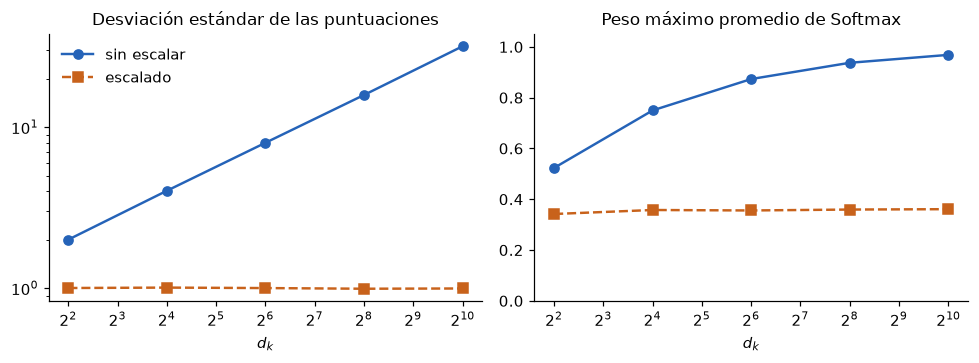

In [19]:
def experimento_escala(dims=(4, 16, 64, 256, 1024), n_claves=8, ensayos=2000, semilla=0):
    r = np.random.default_rng(semilla)
    filas = []
    for d in dims:
        q_ = r.normal(size=(ensayos, 1, d))
        k_ = r.normal(size=(ensayos, n_claves, d))
        s = (q_ * k_).sum(axis=-1)                    # (ensayos, n_claves): productos punto
        for nombre, sc in [("sin escalar", s), ("escalado", s / np.sqrt(d))]:
            w = softmax(sc, axis=-1)
            filas.append({"d_k": d, "versión": nombre,
                          "desv. estándar de las puntuaciones": sc.std(),
                          "peso máximo promedio": w.max(axis=-1).mean()})
    return pd.DataFrame(filas)

resultados = experimento_escala()
display(resultados.round(3))

fig, ejes = plt.subplots(1, 2, figsize=(9, 3.4))
for ax, columna, titulo in zip(ejes,
        ["desv. estándar de las puntuaciones", "peso máximo promedio"],
        ["Desviación estándar de las puntuaciones", "Peso máximo promedio de Softmax"]):
    for nombre, color, estilo, marcador in [("sin escalar", AZUL, "-", "o"),
                                            ("escalado", NARANJA, "--", "s")]:
        d_ = resultados[resultados["versión"] == nombre]
        ax.plot(d_["d_k"], d_[columna], estilo, marker=marcador, color=color, lw=1.6, label=nombre)
    ax.set_xscale("log", base=2); ax.set_xlabel("$d_k$"); ax.set_title(titulo)
ejes[0].set_yscale("log")
ejes[1].set_ylim(0, 1.05)
ejes[0].legend(frameon=False)
plt.tight_layout(); plt.show()

**Interpretación.** Sin escalar, la desviación estándar crece como $\sqrt{d_k}$ y el peso máximo se acerca a 1: con $d_k=1024$ el Softmax prácticamente elige un solo token y casi no deja pasar información de los demás. Con el escalado, la desviación estándar se mantiene en 1 y el reparto de la atención se conserva estable al cambiar la dimensión. (Las consecuencias para el entrenamiento, como gradientes muy pequeños en un Softmax saturado, son la razón práctica por la que Vaswani et al. incorporaron este factor.)

## Análisis 2: ¿qué representa cada dimensión?

| Dimensión | Qué controla | Valores típicos |
|---|---|---|
| $n$ | Cuántos tokens hay en la secuencia (cuántas filas) | Variable |
| $d_{model}$ | Ancho de la representación que circula por todo el modelo | 512 (Transformer original), 768 (BERT-base) |
| $d_k$ | Tamaño del espacio donde se **comparan** consultas y claves | $d_{model}/h$ |
| $d_v$ | Tamaño de lo que cada token **aporta** | $d_{model}/h$ |

Las columnas individuales de $Q$, $K$ y $V$ **no son interpretables por sí solas**: lo que importa es la geometría del espacio completo.

## Análisis 3: ¿qué sucede cuando se modifican las puntuaciones de atención?

Experimentemos directamente sobre una fila de puntuaciones: sumar una constante, hacer una puntuación muy grande y **anular** una posición con $-\infty$ (técnica que usaremos para las máscaras).

In [20]:
puntos = np.array([2.0, 1.0, 0.1, -1.0])
tok = ["t1", "t2", "t3", "t4"]

variantes = {
    "originales": puntos,
    "se suma 5 a todas": puntos + 5,
    "t3 sube a 8 (domina)": np.array([2.0, 1.0, 8.0, -1.0]),
    "t1 = -inf (anulado)": np.array([-np.inf, 1.0, 0.1, -1.0]),
}
pd.DataFrame({k: softmax(v) for k, v in variantes.items()}, index=tok).T

,t1,t2,t3,t4
originales,0.638,0.235,0.095,0.032
se suma 5 a todas,0.638,0.235,0.095,0.032
t3 sube a 8 (domina),0.002,0.001,0.996,0.000
t1 = -inf (anulado),0.000,0.649,0.264,0.088


**Conclusiones:**

- Sumar una constante a todas las puntuaciones **no altera** los pesos.
- Elevar una puntuación hace que ese token **domine** la mezcla.
- Una puntuación de $-\infty$ produce un peso **exactamente 0**: ese token queda completamente fuera. Así se implementan las máscaras (sección 11).

# 6. Visualización e interpretación de la atención

**Objetivo:** observar gráficamente las relaciones que se producen entre los tokens.

## 6.1 y 6.2 La matriz de atención: filas y columnas

La matriz de atención $A\in\mathbb{R}^{n\times n}$ se interpreta así:

- **Filas = consultas** (el token que "mira"). La fila $i$ muestra **cómo el token $i$ reparte su atención** entre todos los tokens.
- **Columnas = claves** (el token que "es mirado"). La columna $j$ muestra cuánta atención recibe el token $j$ de los demás.
- Cada **fila suma 1**. Las **columnas no** tienen por qué sumar 1.

## 6.3 Mapas de calor

Un **mapa de calor** colorea cada celda de $A$ según su peso: más oscuro significa mayor atención. Como los vectores aleatorios de la sección 5 no tienen significado, usaremos primero embeddings **diseñados** (el léxico de juguete): con $W_Q=W_K=W_V=I$ (matriz identidad), el producto punto compara directamente los vectores del léxico. Multiplicamos los embeddings por 3 para que las diferencias se noten.

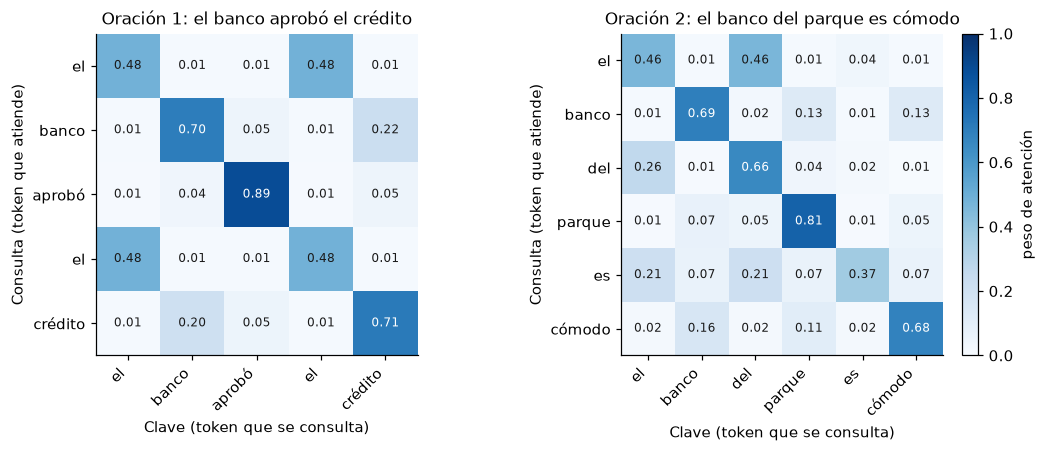

In [21]:
I = np.eye(d_modelo)                      # matriz identidad: no transforma el espacio
Xs1, Xs2 = 3 * X1, 3 * X2

salida_1, A1 = self_attention(Xs1, I, I, I)
salida_2, A2 = self_attention(Xs2, I, I, I)

fig, ejes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [5, 6]})
graficar_atencion(A1, tokenizar(oracion_1), titulo="Oración 1: el banco aprobó el crédito", ax=ejes[0])
im = graficar_atencion(A2, tokenizar(oracion_2), titulo="Oración 2: el banco del parque es cómodo", ax=ejes[1])
fig.colorbar(im, ax=ejes, fraction=0.025, pad=0.02, label="peso de atención")
plt.show()

## 6.4 Identificación de relaciones entre tokens

Lea la fila de "banco" en cada mapa. En ambas oraciones el token conserva la mayor parte de su atención (0.70 y 0.69), pero reparte el resto de forma distinta: en la oración 1 lo dirige sobre todo a "crédito" (0.22) y en la oración 2 a "parque" (0.13) y "cómodo" (0.13). Es decir, **la misma palabra, con el mismo vector de entrada, recibe una mezcla distinta según su contexto.**

Verifiquemos las propiedades de filas y columnas, y midamos cuánto cambió "banco".

In [22]:
print("Suma por filas    (matriz de la sección 5):", pesos.sum(axis=1))
print("Suma por columnas (matriz de la sección 5):", pesos.sum(axis=0), " <- no tienen por qué sumar 1")

# Representación de "banco" en cada oración: antes y después de la atención
i1, i2 = tokenizar(oracion_1).index("banco"), tokenizar(oracion_2).index("banco")
banco_ctx_1, banco_ctx_2 = salida_1[i1], salida_2[i2]
credito, comodo = np.array(lexico["crédito"]), np.array(lexico["cómodo"])

pd.DataFrame({
    "coseno con 'crédito'": [coseno(banco_en_1, credito), coseno(banco_ctx_1, credito),
                             coseno(banco_en_2, credito), coseno(banco_ctx_2, credito)],
    "coseno con 'cómodo'":  [coseno(banco_en_1, comodo), coseno(banco_ctx_1, comodo),
                             coseno(banco_en_2, comodo), coseno(banco_ctx_2, comodo)],
}, index=pd.MultiIndex.from_product([["oración 1", "oración 2"], ["antes (estático)", "después (contextual)"]]))

Suma por filas    (matriz de la sección 5): [1. 1. 1. 1. 1.]
Suma por columnas (matriz de la sección 5): [0.764 1.224 0.84  0.764 1.409]  <- no tienen por qué sumar 1


coseno con 'crédito'  coseno con 'cómodo'
oración 1 antes (estático)                     0.698                0.583
          después (contextual)                 0.822                0.457
oración 2 antes (estático)                     0.698                0.583
          después (contextual)                 0.562                0.686

In [23]:
print("Similitud coseno entre 'banco' (oración 1) y 'banco' (oración 2):")
print(f"  antes de la atención  : {coseno(banco_en_1, banco_en_2):.3f}   (el mismo vector)")
print(f"  después de la atención: {coseno(banco_ctx_1, banco_ctx_2):.3f}   (vectores distintos)")

Similitud coseno entre 'banco' (oración 1) y 'banco' (oración 2):
  antes de la atención  : 1.000   (el mismo vector)
  después de la atención: 0.926   (vectores distintos)


> **Idea clave.** Antes de la atención, "banco" era el mismo vector en ambas oraciones (coseno = 1). Después, el de la oración 1 quedó **más cercano a "crédito"** y el de la oración 2 **más cercano a "cómodo"**. Eso es una representación contextual: el significado se ajustó al entorno. (En el modelo real el efecto se produce con pesos aprendidos, no con matrices identidad, y se repite en muchas capas.)

## 6.5 Comparación con pesos aleatorios

¿Qué pasa si usamos las matrices $W$ aleatorias de la sección 5, sin entrenamiento?

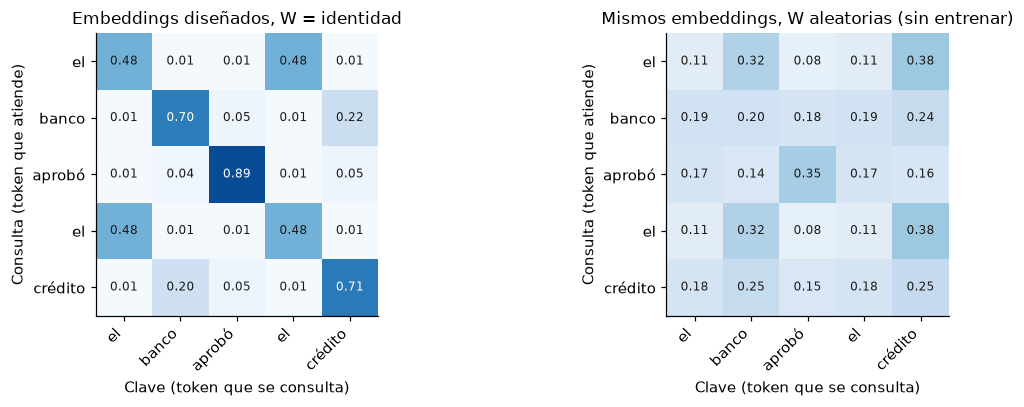

In [24]:
_, A_aleatoria = self_attention(X1, W_Q, W_K, W_V)

fig, ejes = plt.subplots(1, 2, figsize=(11, 3.8))
graficar_atencion(A1, tokenizar(oracion_1), titulo="Embeddings diseñados, W = identidad", ax=ejes[0])
graficar_atencion(A_aleatoria, tokenizar(oracion_1), titulo="Mismos embeddings, W aleatorias (sin entrenar)", ax=ejes[1])
plt.tight_layout(); plt.show()

Con pesos aleatorios el patrón **no refleja relaciones lingüísticas**: el mapa es arbitrario. Un Transformer entrenado aprende matrices $W_Q$, $W_K$ y $W_V$ cuyos productos punto sí reflejan relaciones útiles para su tarea.

> **Advertencia: la atención no es una explicación completa.** Los pesos de atención permiten **observar patrones de interacción** del modelo, pero **no constituyen por sí solos una explicación de cómo el modelo toma sus decisiones**. Hay varias razones: la salida depende también de los valores $V$ (un peso alto sobre un valor casi nulo aporta poco), de las proyecciones posteriores, de las otras cabezas y de las otras capas. La literatura discute este punto (por ejemplo, Jain y Wallace, 2019, y la respuesta de Wiegreffe y Pinter, 2019). Use los mapas de calor como **herramienta de exploración**, no como prueba de causalidad.

### Ejercicio 6

Defina dos oraciones nuevas usando únicamente palabras del léxico (por ejemplo, `"el banco del parque es cómodo"` con otro orden o con repeticiones), genere sus mapas de calor con `self_attention(3 * E[ids], I, I, I)` y describa qué tokens reciben más atención y por qué.

In [25]:
# Escriba aquí su código para el Ejercicio 6.
# Pista: tokenizar(...) -> ids con token_a_id -> E[ids] -> multiplicar por 3 -> self_attention -> graficar_atencion

# 7. Multi-Head Attention

**Objetivo:** comprender por qué el Transformer utiliza varios mecanismos de atención en paralelo.

## 7.1 Limitaciones de una única cabeza de atención

Con una sola cabeza, cada token produce **un único reparto de atención**, es decir, **una sola mezcla**. Pero una palabra puede necesitar, a la vez, información de varios tipos: quién es su sujeto, a qué sustantivo se refiere, qué palabra la modifica, qué significado tiene en este dominio. Un solo promedio ponderado tiene que **comprimir todas esas necesidades en un único patrón**.

## 7.2 El concepto de cabeza (*head*)

Una **cabeza** es una instancia completa del mecanismo Self-Attention con **sus propias matrices** $W_Q$, $W_K$ y $W_V$. Con $h$ cabezas, el modelo calcula $h$ patrones de atención **distintos y en paralelo**.

## 7.3 a 7.6 Proyecciones, paralelismo, concatenación y proyección de salida

1. **Proyecciones independientes.** Cada cabeza $i$ tiene su propio $W_Q^{(i)},W_K^{(i)},W_V^{(i)}$, de forma $(d_{model},\,d_{head})$ con $d_{head}=d_{model}/h$.
2. **Procesamiento paralelo.** Cada cabeza calcula su atención por separado:

$$
\text{head}_i=\operatorname{Attention}\!\left(QW_Q^{(i)},\;KW_K^{(i)},\;VW_V^{(i)}\right)
$$

3. **Concatenación.** Las salidas de las $h$ cabezas (cada una de ancho $d_{head}$) se pegan lado a lado y recuperan el ancho $d_{model}$.
4. **Proyección de salida.** Una matriz $W_O\in\mathbb{R}^{d_{model}\times d_{model}}$ mezcla la información de todas las cabezas:

$$
\operatorname{MultiHead}(Q,K,V)=\operatorname{Concat}(\text{head}_1,\ldots,\text{head}_h)\,W_O
$$

En **self**-attention, $Q$, $K$ y $V$ son todos la misma entrada $X$.

## 7.7 Single-Head frente a Multi-Head

| | Single-Head | Multi-Head |
|---|---|---|
| Patrones de atención por token | 1 | $h$ |
| Dimensión por cabeza | $d_{model}$ | $d_{model}/h$ |
| Parámetros (proyecciones de entrada y salida) | $4\,d_{model}^2$ | $4\,d_{model}^2$ (los mismos) |
| Capacidad de capturar relaciones distintas | Limitada | Mayor |

La diferencia no está en tener más parámetros: el costo total se mantiene porque cada cabeza trabaja en un espacio más pequeño. Lo que se gana es **diversidad**: cada cabeza puede especializarse en un tipo de relación.

## Práctica: Multi-Head con NumPy

Implementaremos 2 cabezas sobre $X_1$ escalado ($d_{model}=6$, por tanto $d_{head}=3$). Las matrices son aleatorias, así que las cabezas no estarán especializadas en nada concreto; lo importante es ver que **producen mapas distintos** y entender el flujo de las dimensiones.

In [26]:
def atencion_multicabeza(X, Wq, Wk, Wv, Wo):
    """Wq, Wk, Wv: listas con una matriz (d_model, d_head) por cabeza. Wo: (h*d_head, d_model)."""
    salidas, pesos_cabezas = [], []
    for wq, wk, wv in zip(Wq, Wk, Wv):
        salida_h, pesos_h = self_attention(X, wq, wk, wv)      # una cabeza completa
        salidas.append(salida_h)                                # (n, d_head)
        pesos_cabezas.append(pesos_h)                           # (n, n)
    concatenado = np.concatenate(salidas, axis=-1)              # (n, h * d_head)
    return concatenado @ Wo, pesos_cabezas, concatenado         # (n, d_model)

h = 2
d_head = d_modelo // h                                          # 6 / 2 = 3
rng = np.random.default_rng(11)

escala = 1 / np.sqrt(d_modelo)          # pesos pequeños: evita que el Softmax se sature
Wq_c = [rng.normal(size=(d_modelo, d_head)) * escala for _ in range(h)]
Wk_c = [rng.normal(size=(d_modelo, d_head)) * escala for _ in range(h)]
Wv_c = [rng.normal(size=(d_modelo, d_head)) * escala for _ in range(h)]
Wo   = rng.normal(size=(h * d_head, d_modelo)) * escala

salida_mh, pesos_mh, concat = atencion_multicabeza(Xs1, Wq_c, Wk_c, Wv_c, Wo)

print(f"Entrada X          : {Xs1.shape}   (n, d_model)")
print(f"Cada cabeza produce : {(Xs1.shape[0], d_head)}  (n, d_head)")
print(f"Concatenación       : {concat.shape}   (n, h * d_head)")
print(f"Después de W_O      : {salida_mh.shape}   (n, d_model)  <- vuelve al ancho original")

Entrada X          : (5, 6)   (n, d_model)
Cada cabeza produce : (5, 3)  (n, d_head)
Concatenación       : (5, 6)   (n, h * d_head)
Después de W_O      : (5, 6)   (n, d_model)  <- vuelve al ancho original


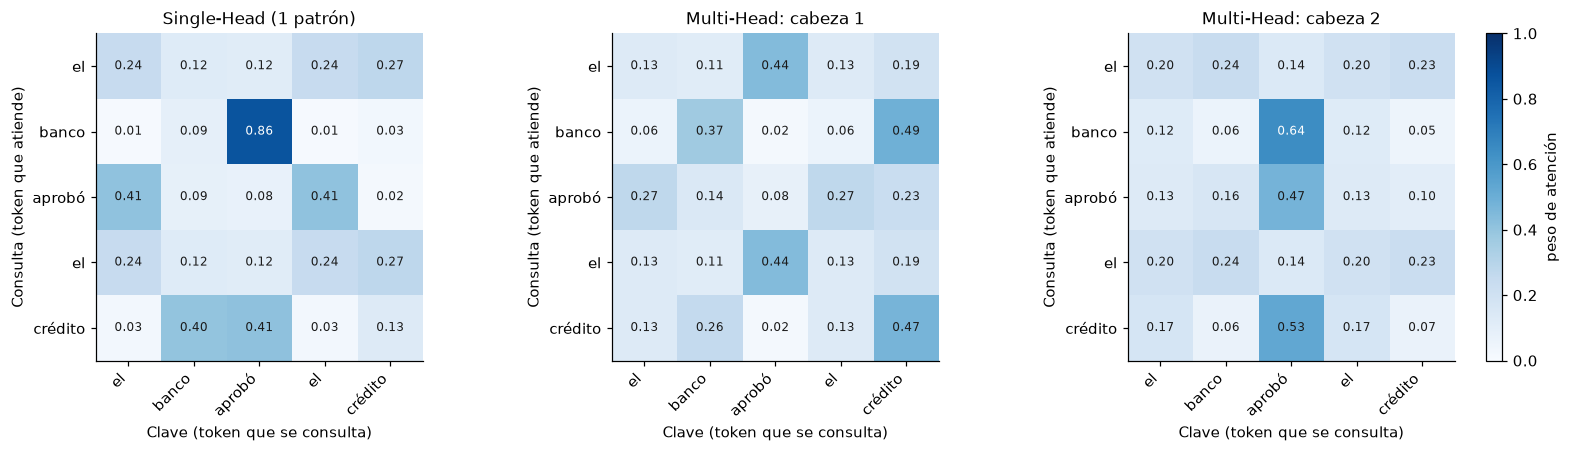

Parámetros Multi-Head (2 cabezas): 144
Parámetros Single-Head            : 144


In [27]:
tokens_1 = tokenizar(oracion_1)
_, pesos_single = self_attention(Xs1, *(rng.normal(size=(d_modelo, d_modelo)) * escala for _ in range(3)))

fig, ejes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
graficar_atencion(pesos_single, tokens_1, titulo="Single-Head (1 patrón)", ax=ejes[0])
graficar_atencion(pesos_mh[0], tokens_1, titulo="Multi-Head: cabeza 1", ax=ejes[1])
im = graficar_atencion(pesos_mh[1], tokens_1, titulo="Multi-Head: cabeza 2", ax=ejes[2])
fig.colorbar(im, ax=ejes, fraction=0.02, pad=0.02, label="peso de atención")
plt.show()

# Conteo de parámetros: Multi-Head no usa más parámetros que Single-Head
params_mh = sum(w.size for w in Wq_c + Wk_c + Wv_c) + Wo.size
params_single = 4 * d_modelo ** 2
print(f"Parámetros Multi-Head ({h} cabezas): {params_mh}")
print(f"Parámetros Single-Head            : {params_single}")

**Observaciones.** Las dos cabezas reparten la atención de **manera diferente** sobre la misma oración; con una sola cabeza habría un único patrón. Después de la proyección $W_O$, la información de ambas cabezas queda combinada en un vector de ancho $d_{model}$.

En modelos entrenados, algunos estudios empíricos (por ejemplo, Clark et al., 2019, sobre BERT) han encontrado cabezas con patrones reconocibles, como atender al token anterior o al siguiente; otros trabajos muestran que varias cabezas son redundantes. No se debe asumir que cada cabeza tiene un rol limpio y único.

# 8. Información posicional: Positional Encoding

**Objetivo:** comprender cómo el Transformer incorpora el orden de los tokens.

## 8.1 y 8.2 ¿Por qué importa el orden y qué limitación tiene la atención?

Compare:

- *El perro muerde al hombre.*
- *El hombre muerde al perro.*

Tienen las mismas palabras y significados opuestos. Pero la atención, tal como la construimos, **no distingue posiciones**: calcula productos punto entre vectores y mezcla sus valores, y esas operaciones no usan el lugar que ocupa cada token. Si se permutan los tokens de entrada, las salidas se permutan igual, pero **cada token recibe exactamente el mismo vector**. Comprobémoslo.

In [28]:
rng = np.random.default_rng(8)
d8 = 8
emb = {t: rng.normal(size=d8) for t in ["perro", "muerde", "hombre"]}      # embeddings aleatorios

orden_a = ["perro", "muerde", "hombre"]
orden_b = ["hombre", "muerde", "perro"]
Xa = np.array([emb[t] for t in orden_a])
Xb = np.array([emb[t] for t in orden_b])

# Pesos escalados por 1/sqrt(d) para que el Softmax no se sature (ver sección 5)
Wq8, Wk8, Wv8 = (rng.normal(size=(d8, d8)) / np.sqrt(d8) for _ in range(3))
sal_a, _ = self_attention(Xa, Wq8, Wk8, Wv8)
sal_b, _ = self_attention(Xb, Wq8, Wk8, Wv8)

print("Sin información posicional, la salida de cada token no depende del orden:")
for token in orden_a:
    va, vb = sal_a[orden_a.index(token)], sal_b[orden_b.index(token)]
    print(f"  {token:<7} orden A vs orden B -> misma salida: {np.allclose(va, vb)}"
          f"   (diferencia máxima = {np.abs(va - vb).max():.1e})")

Sin información posicional, la salida de cada token no depende del orden:
  perro   orden A vs orden B -> misma salida: True   (diferencia máxima = 1.7e-16)
  muerde  orden A vs orden B -> misma salida: True   (diferencia máxima = 2.2e-16)
  hombre  orden A vs orden B -> misma salida: True   (diferencia máxima = 1.1e-16)


> **Idea clave.** Sin información de posición, "perro muerde hombre" y "hombre muerde perro" producen **la misma representación para cada token**. El modelo no puede distinguir quién muerde a quién. Hay que **inyectar el orden** en los embeddings.

## 8.3 Embeddings posicionales

La idea es sumar a cada embedding un vector que **identifica su posición**: 

$$
X_{\text{entrada}}=X_{\text{tokens}}+PE
$$

donde $PE\in\mathbb{R}^{n\times d_{model}}$ tiene un vector distinto para cada posición. Hay dos enfoques:

| Enfoque | Cómo se obtiene $PE$ | Ejemplo |
|---|---|---|
| **Aprendido** | Una tabla de embeddings de posición que se entrena junto con el modelo | BERT, GPT-2 |
| **Sinusoidal (fijo)** | Una fórmula determinista con senos y cosenos | Transformer original |

Existen otras variantes más recientes (posiciones relativas, rotatorias), que no se tratan aquí.

## 8.4 Codificación posicional sinusoidal

$$
PE_{(pos,\,2i)}=\sin\!\left(\frac{pos}{10000^{\,2i/d_{model}}}\right),\qquad
PE_{(pos,\,2i+1)}=\cos\!\left(\frac{pos}{10000^{\,2i/d_{model}}}\right)
$$

| Símbolo | Significado |
|---|---|
| $pos$ | Posición del token en la secuencia (0, 1, 2, ...) |
| $i$ | Índice del **par** de dimensiones (0, 1, ..., $d_{model}/2-1$) |
| $2i$, $2i+1$ | Dimensiones pares usan seno; impares usan coseno |
| $10000^{2i/d_{model}}$ | Controla la **longitud de onda**: dimensiones bajas oscilan rápido, altas muy lento |

**Intuición.** Es como un reloj con muchas manecillas que giran a velocidades distintas (o un contador binario): una combinación de valores rápidos y lentos identifica de forma única cada posición. Además, la posición $pos+k$ se puede obtener como una transformación lineal de la posición $pos$, lo que facilita que el modelo aprenda a razonar sobre **distancias relativas**.

In [29]:
def codificacion_posicional(n_pos, d_model):
    """Matriz PE de forma (n_pos, d_model) con la fórmula sinusoidal."""
    pos = np.arange(n_pos)[:, None]                              # (n_pos, 1)
    i = np.arange(d_model // 2)[None, :]                         # (1, d_model/2)
    angulos = pos / np.power(10000.0, 2 * i / d_model)           # (n_pos, d_model/2)
    PE = np.zeros((n_pos, d_model))
    PE[:, 0::2] = np.sin(angulos)                                # dimensiones pares
    PE[:, 1::2] = np.cos(angulos)                                # dimensiones impares
    return PE

PE_pequena = codificacion_posicional(4, 6)
print("PE para 4 posiciones y d_model = 6 (cada fila identifica una posición):")
display(pd.DataFrame(PE_pequena, index=[f"pos {p}" for p in range(4)],
                     columns=[f"dim {k}" for k in range(6)]))
print("Posición 0: seno(0) = 0 y coseno(0) = 1, de ahí el patrón [0, 1, 0, 1, 0, 1].")

PE para 4 posiciones y d_model = 6 (cada fila identifica una posición):


,dim 0,dim 1,dim 2,dim 3,dim 4,dim 5
pos 0,0.000,1.000,0.000,1.000,0.000,1.000
pos 1,0.841,0.540,0.046,0.999,0.002,1.000
pos 2,0.909,-0.416,0.093,0.996,0.004,1.000
pos 3,0.141,-0.990,0.139,0.990,0.006,1.000


Posición 0: seno(0) = 0 y coseno(0) = 1, de ahí el patrón [0, 1, 0, 1, 0, 1].


## 8.6 Visualización de las representaciones posicionales

Veamos $PE$ completo (50 posiciones, $d_{model}=64$) como mapa de calor y algunas de sus dimensiones como curvas. Los valores van de $-1$ a $1$, por eso usamos una escala **divergente** con el cero en un color neutro.

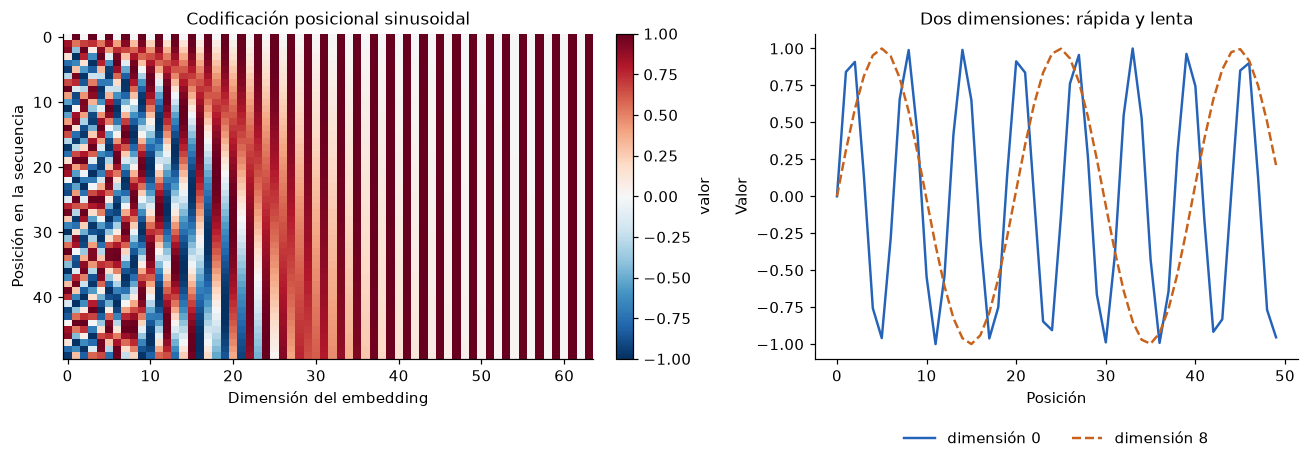

In [30]:
PE = codificacion_posicional(50, 64)

fig, ejes = plt.subplots(1, 2, figsize=(12, 4.4), gridspec_kw={"width_ratios": [1.2, 1]})

im = ejes[0].imshow(PE, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
ejes[0].set_xlabel("Dimensión del embedding"); ejes[0].set_ylabel("Posición en la secuencia")
ejes[0].set_title("Codificación posicional sinusoidal")
fig.colorbar(im, ax=ejes[0], fraction=0.046, pad=0.04, label="valor")

for dim, color, estilo in [(0, AZUL, "-"), (8, NARANJA, "--")]:
    ejes[1].plot(PE[:, dim], estilo, color=color, lw=1.6, label=f"dimensión {dim}")
ejes[1].set_xlabel("Posición"); ejes[1].set_ylabel("Valor"); ejes[1].set_title("Dos dimensiones: rápida y lenta")
ejes[1].legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2)
plt.tight_layout(); plt.show()

**Lectura.** A la izquierda, las **primeras** dimensiones (columnas a la izquierda) oscilan rápido al avanzar las posiciones; las **últimas** casi no cambian. A la derecha se ven dos dimensiones: la 0 oscila rápido y la 8 mucho más lento. La combinación identifica cada fila.

Veamos también la **similitud entre posiciones**: el producto punto $PE_{pos}\cdot PE_{pos'}$ solo depende de la distancia $\lvert pos-pos'\rvert$ y tiende a disminuir al alejarse, aunque no siempre de forma estricta. Así el modelo puede "sentir" la cercanía entre tokens.

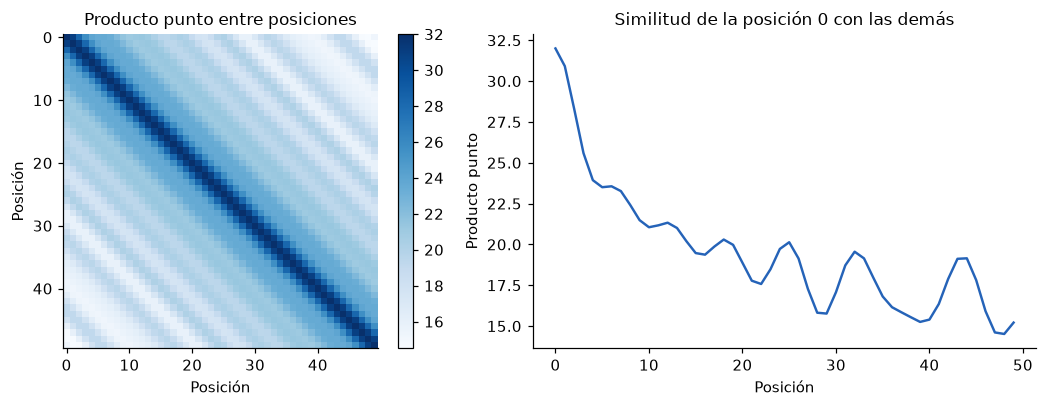

In [31]:
similitud_pos = PE @ PE.T

fig, ejes = plt.subplots(1, 2, figsize=(10.5, 3.8))
im = ejes[0].imshow(similitud_pos, cmap="Blues")
ejes[0].set_title("Producto punto entre posiciones"); ejes[0].set_xlabel("Posición"); ejes[0].set_ylabel("Posición")
fig.colorbar(im, ax=ejes[0], fraction=0.046, pad=0.04)

ejes[1].plot(similitud_pos[0], color=AZUL, lw=1.6)
ejes[1].set_title("Similitud de la posición 0 con las demás")
ejes[1].set_xlabel("Posición"); ejes[1].set_ylabel("Producto punto")
plt.tight_layout(); plt.show()

## 8.5 Combinación de embeddings de tokens y posiciones, y comparación de dos órdenes

Sumamos $PE$ a los embeddings y repetimos el experimento de "perro muerde hombre". (En el Transformer original los embeddings se multiplican por $\sqrt{d_{model}}$ antes de sumar, para equilibrar su magnitud con la de $PE$; aquí los embeddings aleatorios ya tienen una escala comparable.)

In [32]:
PE8 = codificacion_posicional(3, d8)

sal_a_pe, _ = self_attention(Xa + PE8, Wq8, Wk8, Wv8)
sal_b_pe, _ = self_attention(Xb + PE8, Wq8, Wk8, Wv8)

print("Con codificación posicional, la salida de cada token SÍ depende del orden:")
for token in orden_a:
    va, vb = sal_a_pe[orden_a.index(token)], sal_b_pe[orden_b.index(token)]
    print(f"  {token:<7} orden A vs orden B -> misma salida: {np.allclose(va, vb)}"
          f"   (diferencia máxima = {np.abs(va - vb).max():.3f})")

Con codificación posicional, la salida de cada token SÍ depende del orden:
  perro   orden A vs orden B -> misma salida: False   (diferencia máxima = 0.891)
  muerde  orden A vs orden B -> misma salida: False   (diferencia máxima = 0.495)
  hombre  orden A vs orden B -> misma salida: False   (diferencia máxima = 1.053)


> **Idea clave.** Al sumar $PE$, el vector de entrada de "perro" en la primera posición es distinto del de "perro" en la tercera, y por tanto sus salidas difieren. El Transformer puede distinguir *quién* muerde a *quién*. Observe que el orden se **añade** a los datos; no está en la mecánica de la atención.

# 9. Arquitectura completa del Transformer

**Objetivo:** comprender cómo se conectan los mecanismos estudiados para formar la arquitectura.

## 9.1 y 9.2 Arquitectura general: Encoder y Decoder

El Transformer original (Vaswani et al., 2017) para traducción tiene dos partes:

- **Encoder:** lee la secuencia de entrada y produce una representación contextual de cada token (con atención **bidireccional**: cada token ve a todos los demás).
- **Decoder:** genera la secuencia de salida token por token. Usa atención **causal** (no ve el futuro) y, además, una atención **cruzada** (*cross-attention*) hacia las salidas del encoder: sus consultas $Q$ vienen del decoder y sus claves y valores $K,V$ vienen del encoder.

## 9.3 a 9.6 El bloque Transformer

Tanto el encoder como el decoder se construyen **apilando el mismo bloque** $N$ veces. Un bloque de encoder contiene:

| Paso | Componente | Función |
|---|---|---|
| 1 | Entrada + codificación posicional | Embeddings con información de orden |
| 2 | **Multi-Head Self-Attention** | Cada token recoge información de los demás |
| 3 | **Conexión residual** + **Layer Normalization** ("Add & Norm") | Conserva la entrada original y estabiliza la escala |
| 4 | **Feed-Forward Network (FFN)** | Transformación no lineal aplicada a cada token por separado |
| 5 | Segunda conexión residual + Layer Normalization | Igual que el paso 3 |

### Add & Norm: conexión residual y normalización

$$
\text{salida}=\operatorname{LayerNorm}\big(x+\operatorname{Subcapa}(x)\big)
$$

- **Conexión residual** ($x+\operatorname{Subcapa}(x)$): la subcapa solo aprende una **corrección** sobre la entrada, y el gradiente puede fluir directamente hacia capas anteriores, lo que hace posible entrenar redes profundas.
- **Layer Normalization**: normaliza **cada token** a lo largo de sus $d_{model}$ componentes y luego aplica una escala y un desplazamiento aprendibles:

$$
\operatorname{LayerNorm}(\mathbf{x})=\boldsymbol{\gamma}\odot\frac{\mathbf{x}-\mu}{\sqrt{\sigma^{2}+\varepsilon}}+\boldsymbol{\beta}
$$

donde $\mu$ y $\sigma^2$ son la media y la varianza de los componentes de $\mathbf{x}$.

### Feed-Forward Network

$$
\operatorname{FFN}(\mathbf{x})=\max(0,\;\mathbf{x}W_1+\mathbf{b}_1)\,W_2+\mathbf{b}_2
$$

Dos capas lineales con una activación no lineal (ReLU en el original; GELU en modelos más recientes). Se aplica **a cada token por separado y con los mismos pesos**. La dimensión intermedia $d_{ff}$ suele ser $4\,d_{model}$.

**¿Por qué hacen falta las dos subcapas?** La atención **mezcla información entre tokens** (es una combinación lineal de los valores). La FFN **procesa cada token** con una transformación no lineal. Una sin la otra sería insuficiente.

### Profundidad

Apilar $N$ bloques (6 en el original, 12 en BERT-base) permite **refinar las representaciones por etapas**: cada capa recibe como entrada las representaciones contextuales de la anterior y puede relacionarlas de nuevas formas. Trabajos de análisis en BERT sugieren que las capas inferiores capturan información más superficial y las superiores información más abstracta, aunque no es una separación estricta.

Dibujemos un bloque para ver el recorrido de los datos, incluidas las conexiones residuales.

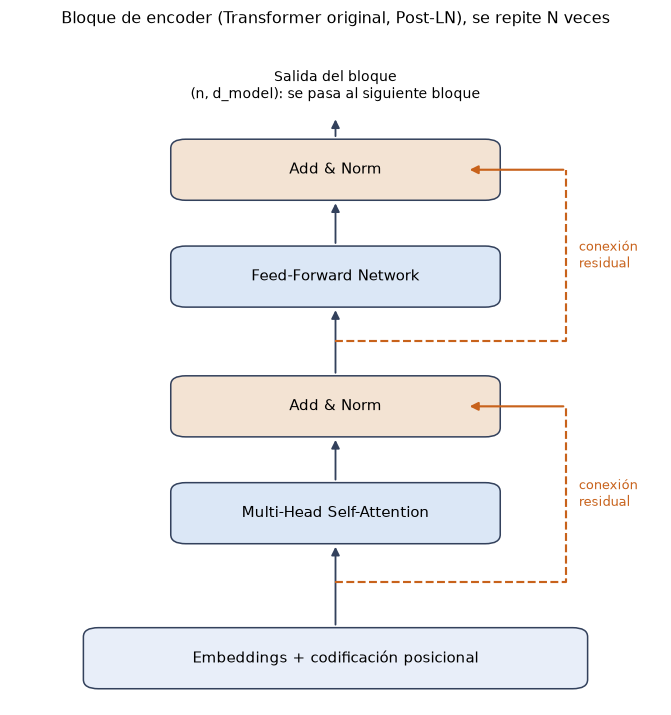

In [33]:
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

def dibujar_bloque_encoder():
    fig, ax = plt.subplots(figsize=(6.2, 6.6))
    ax.set_xlim(-2.6, 2.6); ax.set_ylim(-0.6, 8.2); ax.axis("off")
    borde = "#33415c"

    def caja(y, texto, color, w=2.6):
        ax.add_patch(FancyBboxPatch((-w / 2, y - 0.38), w, 0.76, boxstyle="round,pad=0.02,rounding_size=0.12",
                                    fc=color, ec=borde, lw=1))
        ax.text(0, y, texto, ha="center", va="center", fontsize=9.5)

    def flecha(y0, y1, x=0.0):
        ax.add_patch(FancyArrowPatch((x, y0), (x, y1), arrowstyle="-|>", mutation_scale=11, lw=1.2, color=borde))

    def residual(y_ini, y_fin):
        ax.plot([0, 1.85, 1.85], [y_ini, y_ini, y_fin], color=NARANJA, lw=1.4, ls="--")
        ax.add_patch(FancyArrowPatch((1.85, y_fin), (1.05, y_fin), arrowstyle="-|>", mutation_scale=11,
                                     lw=1.4, color=NARANJA))
        ax.text(1.95, (y_ini + y_fin) / 2, "conexión\nresidual", color=NARANJA, fontsize=8.5, va="center", ha="left")

    caja(0.0, "Embeddings + codificación posicional", "#e8eef9", w=4.0)
    caja(1.9, "Multi-Head Self-Attention", "#dbe7f6")
    caja(3.3, "Add & Norm", "#f3e3d3")
    caja(5.0, "Feed-Forward Network", "#dbe7f6")
    caja(6.4, "Add & Norm", "#f3e3d3")
    ax.text(0, 7.5, "Salida del bloque\n(n, d_model): se pasa al siguiente bloque", ha="center", va="center", fontsize=9)

    flecha(0.4, 1.5); flecha(2.3, 2.9); flecha(3.7, 4.6); flecha(5.4, 6.0); flecha(6.8, 7.1)
    residual(1.0, 3.3)
    residual(4.15, 6.4)
    ax.set_title("Bloque de encoder (Transformer original, Post-LN), se repite N veces", fontsize=10.5)
    plt.tight_layout(); plt.show()

dibujar_bloque_encoder()

> **Nota.** Esta es la variante del artículo original (*Post-LN*: la normalización va **después** de la suma). Muchos modelos recientes usan *Pre-LN* (la normalización va **antes** de cada subcapa), que suele entrenar con más estabilidad. La idea central no cambia.

## 9.7 Máscaras de atención

Los modelos usan dos tipos de máscara (sección 11): la **máscara de relleno** (*padding mask*), para ignorar tokens de relleno, y la **máscara causal**, para que un token no vea posiciones futuras. El encoder usa solo la primera; el decoder usa ambas.

## Tres familias de modelos

| Familia | Componentes | Atención | Preentrenamiento típico | Ejemplos | Usos habituales |
|---|---|---|---|---|---|
| **Encoder-only** | Solo encoder | Bidireccional | Predecir tokens enmascarados | BERT | Clasificación, búsqueda, embeddings, extracción de entidades |
| **Decoder-only** | Solo decoder (sin cross-attention) | Causal | Predecir el siguiente token | GPT y los asistentes conversacionales actuales | Generación de texto |
| **Encoder-Decoder** | Ambos, con cross-attention | Bidireccional en el encoder, causal en el decoder | Reconstruir o transformar secuencias | T5, Transformer original | Traducción, resumen |

Los modelos de embeddings del tema anterior (como `paraphrase-multilingual-MiniLM-L12-v2`) son **encoders**: transforman un texto en una representación vectorial.

## 9.8 Flujo completo de información

$$
\text{texto}\to\text{tokens}\to\text{IDs}\to\underbrace{\text{embeddings}+PE}_{(n,\,d_{model})}\to
\underbrace{\text{bloque}_1\to\text{bloque}_2\to\cdots\to\text{bloque}_N}_{(n,\,d_{model})\ \text{en cada paso}}\to\text{representaciones contextuales}
$$

La forma $(n,\,d_{model})$ **se conserva** a lo largo de todos los bloques; lo que cambia es el contenido de cada fila, que se va enriqueciendo con el contexto.

## Actividad 9. Diagrama de flujo del recorrido de una secuencia

Use la función `dibujar_flujo` para representar el recorrido de **una oración** por un encoder. Se entrega un ejemplo; modifique las etapas y las formas para su propia oración (tokens, $d_{model}$, número de bloques) y agregue, si lo desea, las etapas de un decoder.

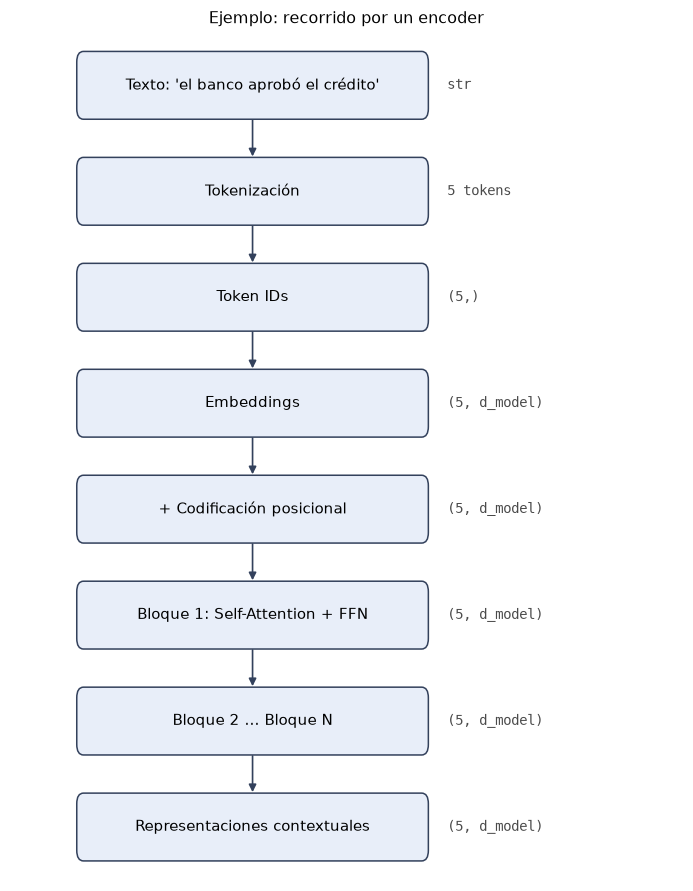

In [34]:
def dibujar_flujo(etapas, titulo="Recorrido de una secuencia"):
    """etapas: lista de (nombre, forma_del_tensor). Dibuja una cadena vertical de cajas."""
    n_et = len(etapas)
    fig, ax = plt.subplots(figsize=(6.4, 0.95 * n_et + 0.6))
    ax.set_xlim(0, 10); ax.set_ylim(0, n_et); ax.axis("off")
    for k, (nombre, forma) in enumerate(etapas):
        y = n_et - 1 - k + 0.5
        ax.add_patch(FancyBboxPatch((1.0, y - 0.3), 5.2, 0.6, boxstyle="round,pad=0.02,rounding_size=0.1",
                                    fc="#e8eef9", ec="#33415c", lw=1))
        ax.text(3.6, y, nombre, ha="center", va="center", fontsize=9.5)
        ax.text(6.5, y, forma, ha="left", va="center", fontsize=9, color="#4a4a4a", family="monospace")
        if k < n_et - 1:
            ax.add_patch(FancyArrowPatch((3.6, y - 0.3), (3.6, y - 0.7), arrowstyle="-|>", mutation_scale=10,
                                         lw=1.1, color="#33415c"))
    ax.set_title(titulo, fontsize=10.5)
    plt.tight_layout(); plt.show()

dibujar_flujo([
    ("Texto: 'el banco aprobó el crédito'",           "str"),
    ("Tokenización",                                   "5 tokens"),
    ("Token IDs",                                      "(5,)"),
    ("Embeddings",                                     "(5, d_model)"),
    ("+ Codificación posicional",                      "(5, d_model)"),
    ("Bloque 1: Self-Attention + FFN",                 "(5, d_model)"),
    ("Bloque 2 ... Bloque N",                          "(5, d_model)"),
    ("Representaciones contextuales",                  "(5, d_model)"),
], titulo="Ejemplo: recorrido por un encoder")

In [35]:
# Escriba aquí su propio diagrama para la Actividad 9:
# dibujar_flujo([("etapa 1", "forma"), ("etapa 2", "forma"), ...], titulo="Mi diagrama")

# 10. Implementación de un bloque Transformer con PyTorch

**Objetivo:** llevar los conceptos matemáticos a una implementación funcional.

Construiremos el bloque pieza por pieza y, en cada una, **verificaremos** que hace lo mismo que la versión de NumPy o que la implementación de referencia de PyTorch. Así comprobamos que "papel y código" coinciden.

## 10.1 Tensores y dimensiones en PyTorch

Un **tensor** es la generalización de vectores y matrices a cualquier número de dimensiones. En NumPy trabajamos con una sola secuencia $(n,\,d_{model})$; en PyTorch se procesan **lotes** de secuencias a la vez, así que aparece una dimensión adicional al inicio (`batch`).

| Tensor | Forma | Descripción |
|---|---|---|
| Entrada de tokens | `(batch, seq_len)` | IDs enteros |
| Embeddings | `(batch, seq_len, d_model)` | Un vector por token |
| Q, K, V (por cabeza) | `(batch, heads, seq_len, d_head)` | Se separan las cabezas en una dimensión propia |
| Matriz de atención | `(batch, heads, seq_len, seq_len)` | Una matriz $n\times n$ por cabeza |
| Salida de atención | `(batch, seq_len, d_model)` | Las cabezas vuelven a concatenarse |

Las operaciones que más usaremos son: `@` (multiplicación de matrices), `.transpose(a, b)` (intercambiar dos dimensiones), `.view(...)` (reinterpretar la forma sin copiar datos) y `torch.softmax(x, dim=-1)` (Softmax a lo largo de la última dimensión).

In [36]:
import math
import torch
import torch.nn as nn

torch.manual_seed(0)
print("Versión de PyTorch:", torch.__version__)

x = torch.arange(24, dtype=torch.float32).view(2, 3, 4)       # (batch=2, seq_len=3, d_model=4)
print("x.shape                   :", tuple(x.shape))
print("x.transpose(1, 2).shape   :", tuple(x.transpose(1, 2).shape), " (intercambia seq_len y d_model)")
print("(x @ x.transpose(1,2)).shape:", tuple((x @ x.transpose(1, 2)).shape),
      " (matriz n x n por cada elemento del lote)")
print("x.view(2, 3, 2, 2).shape  :", tuple(x.view(2, 3, 2, 2).shape), " (d_model=4 se parte en 2 cabezas de 2)")

Versión de PyTorch: 2.15.0+cpu
x.shape                   : (2, 3, 4)
x.transpose(1, 2).shape   : (2, 4, 3)  (intercambia seq_len y d_model)
(x @ x.transpose(1,2)).shape: (2, 3, 3)  (matriz n x n por cada elemento del lote)
x.view(2, 3, 2, 2).shape  : (2, 3, 2, 2)  (d_model=4 se parte en 2 cabezas de 2)


## 10.2 Capa de embeddings

`nn.Embedding(tamaño_del_vocabulario, d_model)` es exactamente la matriz $E$ de la sección 2: una tabla con una fila por token, **entrenable**. Recibe IDs `(batch, seq_len)` y devuelve `(batch, seq_len, d_model)`.

Definimos las dimensiones del modelo. Como las oraciones tienen longitudes distintas (5 y 6 tokens), las agrupamos en un lote **rellenando** con el ID 0 (`<pad>`) al final.

In [37]:
D_MODEL, N_CABEZAS, D_FF = 16, 4, 64        # d_model = 16; 4 cabezas de d_head = 4; FFN de ancho 64
TAM_VOCAB = len(vocabulario)
PAD_ID = token_a_id["<pad>"]

def a_lote(oraciones):
    """Convierte oraciones en un tensor (batch, seq_len), rellenando con <pad> al final."""
    ids = [[token_a_id[t] for t in tokenizar(o)] for o in oraciones]
    n_max = max(len(s) for s in ids)
    return torch.tensor([s + [PAD_ID] * (n_max - len(s)) for s in ids])

ids_lote = a_lote([oracion_1, oracion_2])
print("ids_lote:\n", ids_lote)
print("Forma:", tuple(ids_lote.shape), "-> (batch=2, seq_len=6); la primera fila termina con un <pad>")

capa_embedding = nn.Embedding(TAM_VOCAB, D_MODEL, padding_idx=PAD_ID)
emb_lote = capa_embedding(ids_lote)
print("Embeddings:", tuple(emb_lote.shape), "-> (batch, seq_len, d_model)")

ids_lote:
 tensor([[6, 2, 1, 6, 3, 0],
        [6, 2, 5, 8, 7, 4]])
Forma: (2, 6) -> (batch=2, seq_len=6); la primera fila termina con un <pad>
Embeddings: (2, 6, 16) -> (batch, seq_len, d_model)


## 10.3 Self-Attention (una cabeza)

`nn.Linear(d_model, d_k, bias=False)` calcula $XW$ con una matriz de pesos **aprendible**; por tanto, cada una de las tres proyecciones $W_Q,W_K,W_V$ es una capa lineal sin sesgo. La máscara sigue la misma convención que en NumPy: `True` significa "puede atender". Las posiciones con `False` se llevan a $-\infty$ antes del Softmax.

In [38]:
class AutoAtencion(nn.Module):
    """Self-Attention de una cabeza.  x: (batch, n, d_model) -> (batch, n, d_v)."""
    def __init__(self, d_model, d_k, d_v=None):
        super().__init__()
        self.W_q = nn.Linear(d_model, d_k, bias=False)
        self.W_k = nn.Linear(d_model, d_k, bias=False)
        self.W_v = nn.Linear(d_model, d_v or d_k, bias=False)

    def forward(self, x, mascara=None):
        Q, K, V = self.W_q(x), self.W_k(x), self.W_v(x)
        puntuaciones = Q @ K.transpose(-2, -1) / math.sqrt(Q.size(-1))      # (batch, n, n)
        if mascara is not None:
            puntuaciones = puntuaciones.masked_fill(~mascara, float("-inf"))
        pesos = torch.softmax(puntuaciones, dim=-1)
        return pesos @ V, pesos

# Verificación: copiar los pesos de NumPy (sección 5) y comparar resultados
atencion_torch = AutoAtencion(d_model=6, d_k=4)
with torch.no_grad():
    atencion_torch.W_q.weight.copy_(torch.tensor(W_Q.T))     # nn.Linear guarda la matriz transpuesta
    atencion_torch.W_k.weight.copy_(torch.tensor(W_K.T))
    atencion_torch.W_v.weight.copy_(torch.tensor(W_V.T))
    salida_t, pesos_t = atencion_torch(torch.tensor(X1, dtype=torch.float32).unsqueeze(0))

print("Forma de la salida:", tuple(salida_t.shape), " | forma de los pesos:", tuple(pesos_t.shape))
print("¿PyTorch coincide con NumPy (salida)?", np.allclose(salida_t[0].numpy(), salida, atol=1e-5))
print("¿PyTorch coincide con NumPy (pesos) ?", np.allclose(pesos_t[0].numpy(), pesos, atol=1e-5))

Forma de la salida: (1, 5, 4)  | forma de los pesos: (1, 5, 5)
¿PyTorch coincide con NumPy (salida)? True
¿PyTorch coincide con NumPy (pesos) ? True


## 10.4 Multi-Head Attention

En lugar de crear $h$ capas lineales separadas, se usa **una sola** proyección de ancho $d_{model}$ para $Q$, $K$ y $V$ y luego se **parte** el resultado en $h$ cabezas con `view` y `transpose`. Es matemáticamente equivalente (cada cabeza usa un bloque de columnas de la matriz) pero mucho más eficiente.

Primero seguimos el recorrido de las dimensiones paso a paso:

In [39]:
b, n_, d = emb_lote.shape
h_, dh = N_CABEZAS, D_MODEL // N_CABEZAS
Wq_ = nn.Linear(D_MODEL, D_MODEL, bias=False)

q_ = Wq_(emb_lote)
print(f"1. Proyección Q                 : {tuple(q_.shape)}   (batch, seq_len, d_model)")
q_ = q_.view(b, n_, h_, dh)
print(f"2. view: separar cabezas        : {tuple(q_.shape)}   (batch, seq_len, heads, d_head)")
q_ = q_.transpose(1, 2)
print(f"3. transpose(1, 2)              : {tuple(q_.shape)}   (batch, heads, seq_len, d_head)")
punt_ = q_ @ q_.transpose(-2, -1)
print(f"4. Q @ K^T (aquí K = Q)         : {tuple(punt_.shape)}   (batch, heads, seq_len, seq_len)")
sal_ = (torch.softmax(punt_ / math.sqrt(dh), -1) @ q_)
print(f"5. pesos @ V (aquí V = Q)       : {tuple(sal_.shape)}   (batch, heads, seq_len, d_head)")
sal_ = sal_.transpose(1, 2).contiguous().view(b, n_, D_MODEL)
print(f"6. concatenar cabezas           : {tuple(sal_.shape)}   (batch, seq_len, d_model)")

1. Proyección Q                 : (2, 6, 16)   (batch, seq_len, d_model)
2. view: separar cabezas        : (2, 6, 4, 4)   (batch, seq_len, heads, d_head)
3. transpose(1, 2)              : (2, 4, 6, 4)   (batch, heads, seq_len, d_head)
4. Q @ K^T (aquí K = Q)         : (2, 4, 6, 6)   (batch, heads, seq_len, seq_len)
5. pesos @ V (aquí V = Q)       : (2, 4, 6, 4)   (batch, heads, seq_len, d_head)
6. concatenar cabezas           : (2, 6, 16)   (batch, seq_len, d_model)


In [40]:
class AtencionMultiCabeza(nn.Module):
    """Multi-Head Self-Attention.  x: (batch, n, d_model) -> (batch, n, d_model)."""
    def __init__(self, d_model, n_cabezas):
        super().__init__()
        assert d_model % n_cabezas == 0, "d_model debe ser divisible por el número de cabezas"
        self.h, self.d_head = n_cabezas, d_model // n_cabezas
        self.W_q = nn.Linear(d_model, d_model, bias=False)
        self.W_k = nn.Linear(d_model, d_model, bias=False)
        self.W_v = nn.Linear(d_model, d_model, bias=False)
        self.W_o = nn.Linear(d_model, d_model, bias=False)

    def _separar(self, t):                                    # (b, n, d_model) -> (b, h, n, d_head)
        b, n, _ = t.shape
        return t.view(b, n, self.h, self.d_head).transpose(1, 2)

    def forward(self, x, mascara=None):
        Q, K, V = self._separar(self.W_q(x)), self._separar(self.W_k(x)), self._separar(self.W_v(x))
        puntuaciones = Q @ K.transpose(-2, -1) / math.sqrt(self.d_head)     # (b, h, n, n)
        if mascara is not None:
            puntuaciones = puntuaciones.masked_fill(~mascara, float("-inf"))
        pesos = torch.softmax(puntuaciones, dim=-1)
        cabezas = pesos @ V                                                  # (b, h, n, d_head)
        b, _, n, _ = cabezas.shape
        concatenado = cabezas.transpose(1, 2).contiguous().view(b, n, -1)  # (b, n, d_model)
        return self.W_o(concatenado), pesos

# Verificación contra la implementación de referencia de PyTorch
mha = AtencionMultiCabeza(D_MODEL, N_CABEZAS)
referencia = nn.MultiheadAttention(D_MODEL, N_CABEZAS, bias=False, batch_first=True)
with torch.no_grad():
    referencia.in_proj_weight.copy_(torch.cat([mha.W_q.weight, mha.W_k.weight, mha.W_v.weight], dim=0))
    referencia.out_proj.weight.copy_(mha.W_o.weight)
    mi_salida, mis_pesos = mha(emb_lote)
    sal_ref, pesos_ref = referencia(emb_lote, emb_lote, emb_lote, need_weights=True, average_attn_weights=False)

print("Salida:", tuple(mi_salida.shape), "| pesos:", tuple(mis_pesos.shape))
print("¿Coincide con nn.MultiheadAttention (salida)?", torch.allclose(mi_salida, sal_ref, atol=1e-5))
print("¿Coincide con nn.MultiheadAttention (pesos) ?", torch.allclose(mis_pesos, pesos_ref, atol=1e-5))

Salida: (2, 6, 16) | pesos: (2, 4, 6, 6)
¿Coincide con nn.MultiheadAttention (salida)? True
¿Coincide con nn.MultiheadAttention (pesos) ? True


## 10.5 Codificación posicional

Misma fórmula de la sección 8, calculada una sola vez y guardada como *buffer* (un tensor que viaja con el módulo pero **no se entrena**). Se suma a los embeddings.

In [41]:
class CodificacionPosicional(nn.Module):
    """Suma la codificación sinusoidal.  x: (batch, n, d_model) -> (batch, n, d_model)."""
    def __init__(self, d_model, max_len=512):
        super().__init__()
        pos = torch.arange(max_len).unsqueeze(1).float()
        frecuencia = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe = torch.zeros(max_len, d_model)
        pe[:, 0::2] = torch.sin(pos * frecuencia)
        pe[:, 1::2] = torch.cos(pos * frecuencia)
        self.register_buffer("pe", pe.unsqueeze(0))            # (1, max_len, d_model)

    def forward(self, x):
        return x + self.pe[:, : x.size(1)]

codificador_pos = CodificacionPosicional(D_MODEL)
print("¿Coincide con la versión de NumPy (sección 8)?",
      np.allclose(codificador_pos.pe[0, :10].numpy(), codificacion_posicional(10, D_MODEL), atol=1e-6))

¿Coincide con la versión de NumPy (sección 8)? True


## 10.6 Feed-Forward Network

Dos capas lineales con una no linealidad (ReLU). Se aplica a cada token **de forma independiente** y con los mismos pesos: opera sobre la última dimensión y no mezcla posiciones.

In [42]:
class RedFeedForward(nn.Module):
    """FFN(x) = max(0, x W1 + b1) W2 + b2.  (batch, n, d_model) -> (batch, n, d_model)."""
    def __init__(self, d_model, d_ff):
        super().__init__()
        self.capa1 = nn.Linear(d_model, d_ff)
        self.capa2 = nn.Linear(d_ff, d_model)

    def forward(self, x):
        return self.capa2(torch.relu(self.capa1(x)))

## 10.7 y 10.8 Conexiones residuales, normalización y bloque Transformer

Ensamblamos el bloque del diagrama de la sección 9 (variante Post-LN):

```
x -> Multi-Head Self-Attention -> Add & Norm -> FFN -> Add & Norm -> salida
```

`nn.LayerNorm(d_model)` normaliza cada token a lo largo de sus $d_{model}$ componentes. Para mantener el código sencillo omitimos el *dropout* (una técnica de regularización que no cambia la mecánica que estamos estudiando).

In [43]:
class BloqueTransformer(nn.Module):
    """Un bloque de encoder (Post-LN).  (batch, n, d_model) -> (batch, n, d_model)."""
    def __init__(self, d_model, n_cabezas, d_ff):
        super().__init__()
        self.atencion = AtencionMultiCabeza(d_model, n_cabezas)
        self.norm1 = nn.LayerNorm(d_model)
        self.ffn = RedFeedForward(d_model, d_ff)
        self.norm2 = nn.LayerNorm(d_model)

    def forward(self, x, mascara=None):
        salida_atencion, pesos = self.atencion(x, mascara)
        x = self.norm1(x + salida_atencion)          # conexión residual + normalización
        x = self.norm2(x + self.ffn(x))              # conexión residual + normalización
        return x, pesos


class MiniTransformer(nn.Module):
    """Embeddings + posición + N bloques.  ids: (batch, n) -> (batch, n, d_model)."""
    def __init__(self, tam_vocab, d_model, n_cabezas, d_ff, n_capas, pad_id=0):
        super().__init__()
        self.d_model = d_model
        self.embedding = nn.Embedding(tam_vocab, d_model, padding_idx=pad_id)
        self.posicion = CodificacionPosicional(d_model)
        self.bloques = nn.ModuleList([BloqueTransformer(d_model, n_cabezas, d_ff) for _ in range(n_capas)])

    def forward(self, ids, mascara=None):
        x = self.posicion(self.embedding(ids) * math.sqrt(self.d_model))
        todos_los_pesos = []
        for bloque in self.bloques:
            x, pesos = bloque(x, mascara)
            todos_los_pesos.append(pesos)
        return x, todos_los_pesos

modelo = MiniTransformer(TAM_VOCAB, D_MODEL, N_CABEZAS, D_FF, n_capas=2, pad_id=PAD_ID)
modelo.eval()
print(modelo)

MiniTransformer(
  (embedding): Embedding(9, 16, padding_idx=0)
  (posicion): CodificacionPosicional()
  (bloques): ModuleList(
    (0-1): 2 x BloqueTransformer(
      (atencion): AtencionMultiCabeza(
        (W_q): Linear(in_features=16, out_features=16, bias=False)
        (W_k): Linear(in_features=16, out_features=16, bias=False)
        (W_v): Linear(in_features=16, out_features=16, bias=False)
        (W_o): Linear(in_features=16, out_features=16, bias=False)
      )
      (norm1): LayerNorm((16,), eps=1e-05, elementwise_affine=True, bias=True)
      (ffn): RedFeedForward(
        (capa1): Linear(in_features=16, out_features=64, bias=True)
        (capa2): Linear(in_features=64, out_features=16, bias=True)
      )
      (norm2): LayerNorm((16,), eps=1e-05, elementwise_affine=True, bias=True)
    )
  )
)


## 10.9 Ejecución de una secuencia de entrada

Pasamos el lote de dos oraciones por el modelo y seguimos las formas **a través de cada etapa**.

In [44]:
with torch.no_grad():
    x = modelo.embedding(ids_lote) * math.sqrt(D_MODEL)
    print(f"Tokens (IDs)                 : {tuple(ids_lote.shape)}   (batch, seq_len)")
    print(f"Embeddings                   : {tuple(x.shape)}   (batch, seq_len, d_model)")
    x = modelo.posicion(x)
    print(f"+ codificación posicional    : {tuple(x.shape)}   (batch, seq_len, d_model)")
    for k, bloque in enumerate(modelo.bloques, start=1):
        sal_at, pesos_k = bloque.atencion(x)
        print(f"Bloque {k} | atención (pesos)  : {tuple(pesos_k.shape)}   (batch, heads, seq_len, seq_len)")
        print(f"Bloque {k} | atención (salida) : {tuple(sal_at.shape)}   (batch, seq_len, d_model)")
        x = bloque.norm1(x + sal_at)
        x = bloque.norm2(x + bloque.ffn(x))
        print(f"Bloque {k} | salida del bloque : {tuple(x.shape)}   (batch, seq_len, d_model)")

    oculto, lista_pesos = modelo(ids_lote)
print("\n¿El recorrido manual coincide con modelo(ids)?", torch.allclose(x, oculto, atol=1e-6))

Tokens (IDs)                 : (2, 6)   (batch, seq_len)
Embeddings                   : (2, 6, 16)   (batch, seq_len, d_model)
+ codificación posicional    : (2, 6, 16)   (batch, seq_len, d_model)
Bloque 1 | atención (pesos)  : (2, 4, 6, 6)   (batch, heads, seq_len, seq_len)
Bloque 1 | atención (salida) : (2, 6, 16)   (batch, seq_len, d_model)
Bloque 1 | salida del bloque : (2, 6, 16)   (batch, seq_len, d_model)
Bloque 2 | atención (pesos)  : (2, 4, 6, 6)   (batch, heads, seq_len, seq_len)
Bloque 2 | atención (salida) : (2, 6, 16)   (batch, seq_len, d_model)
Bloque 2 | salida del bloque : (2, 6, 16)   (batch, seq_len, d_model)

¿El recorrido manual coincide con modelo(ids)? True


## 10.10 Inspección de dimensiones y salidas

Comprobamos propiedades que **deben** cumplirse y contamos los parámetros de cada componente.

In [45]:
pesos_capa1 = lista_pesos[0]
print("Forma de la salida del modelo:", tuple(oculto.shape), "== (batch, seq_len, d_model)")
print("Cada fila de la matriz de atención suma 1:", torch.allclose(pesos_capa1.sum(-1), torch.ones(2, N_CABEZAS, 6)))
print("Hay NaN en la salida:", bool(torch.isnan(oculto).any()))

def n_parametros(modulo):
    return sum(p.numel() for p in modulo.parameters())

bloque0 = modelo.bloques[0]
tabla_parametros = pd.DataFrame({
    "componente": ["Embedding", "Multi-Head Attention (por bloque)", "Feed-Forward (por bloque)",
                   "LayerNorm x2 (por bloque)", "Total del modelo"],
    "parámetros": [n_parametros(modelo.embedding), n_parametros(bloque0.atencion), n_parametros(bloque0.ffn),
                   n_parametros(bloque0.norm1) + n_parametros(bloque0.norm2), n_parametros(modelo)],
})
display(tabla_parametros)
print(f"Atención: 4 x d_model^2 = {4 * D_MODEL**2};  FFN: 2 x d_model x d_ff + sesgos = "
      f"{2 * D_MODEL * D_FF + D_FF + D_MODEL}")

Forma de la salida del modelo: (2, 6, 16) == (batch, seq_len, d_model)
Cada fila de la matriz de atención suma 1: True
Hay NaN en la salida: False


,componente,parámetros
0,Embedding,144
1,Multi-Head Attention (por bloque),1024
2,Feed-Forward (por bloque),2128
3,LayerNorm x2 (por bloque),64
4,Total del modelo,6576


Atención: 4 x d_model^2 = 1024;  FFN: 2 x d_model x d_ff + sesgos = 2128


> **Idea clave.** La forma `(batch, seq_len, d_model)` entra y sale de cada bloque; por eso se pueden **apilar tantos bloques como se desee**. En un modelo real los pesos serían entrenados; aquí son aleatorios, de modo que las representaciones de salida aún no tienen significado lingüístico. Lo que sí hemos verificado es que la mecánica es correcta: coincide con NumPy y con la implementación de referencia de PyTorch.

# 11. Máscaras de atención y generación de secuencias

**Objetivo:** comprender cómo se restringe la información disponible durante el procesamiento.

## 11.1 ¿Qué es una máscara de atención?

Es una matriz de verdadero/falso que indica **qué pares (consulta, clave) pueden relacionarse**. Las posiciones prohibidas reciben una puntuación de $-\infty$ antes del Softmax, de modo que su peso final es exactamente **0** (lo comprobamos en la sección 5).

## 11.2 Padding mask (máscara de relleno)

Para procesar varias oraciones de distinta longitud en un lote se **rellenan** las cortas con `<pad>`. Esos tokens no aportan información y **no deben recibir atención**. La máscara de relleno tiene `False` en las columnas (claves) que corresponden a `<pad>`.

## 11.3 Causal mask (máscara causal)

Al **generar** texto, el token en la posición $i$ solo puede usar los tokens $1,\dots,i$: el futuro todavía no existe. La máscara causal es una matriz **triangular inferior** (`True` en y debajo de la diagonal).

## 11.4 Encoder frente a decoder

| | Encoder | Decoder |
|---|---|---|
| Máscara causal | No | Sí |
| Máscara de relleno | Sí | Sí |
| Cada token ve | Toda la secuencia (izquierda y derecha) | Solo sí mismo y los anteriores |
| Uso | Comprender | Generar |

## Práctica: construir y visualizar las máscaras

In [46]:
n_seq = ids_lote.size(1)

mascara_causal = torch.tril(torch.ones(n_seq, n_seq, dtype=torch.bool))          # (n, n)
mascara_relleno = (ids_lote != PAD_ID)[:, None, None, :]                           # (batch, 1, 1, n)
mascara_total = mascara_relleno & mascara_causal                                   # (batch, 1, n, n)

print("Máscara causal (True = puede atender):")
print(mascara_causal.int().numpy())
print("\nMáscara de relleno de la oración 1 (la última posición es <pad>):", mascara_relleno[0, 0, 0].int().tolist())
print("Forma de la máscara total:", tuple(mascara_total.shape), "-> se propaga a (batch, heads, n, n)")

Máscara causal (True = puede atender):
[[1 0 0 0 0 0]
 [1 1 0 0 0 0]
 [1 1 1 0 0 0]
 [1 1 1 1 0 0]
 [1 1 1 1 1 0]
 [1 1 1 1 1 1]]

Máscara de relleno de la oración 1 (la última posición es <pad>): [1, 1, 1, 1, 1, 0]
Forma de la máscara total: (2, 1, 6, 6) -> se propaga a (batch, heads, n, n)


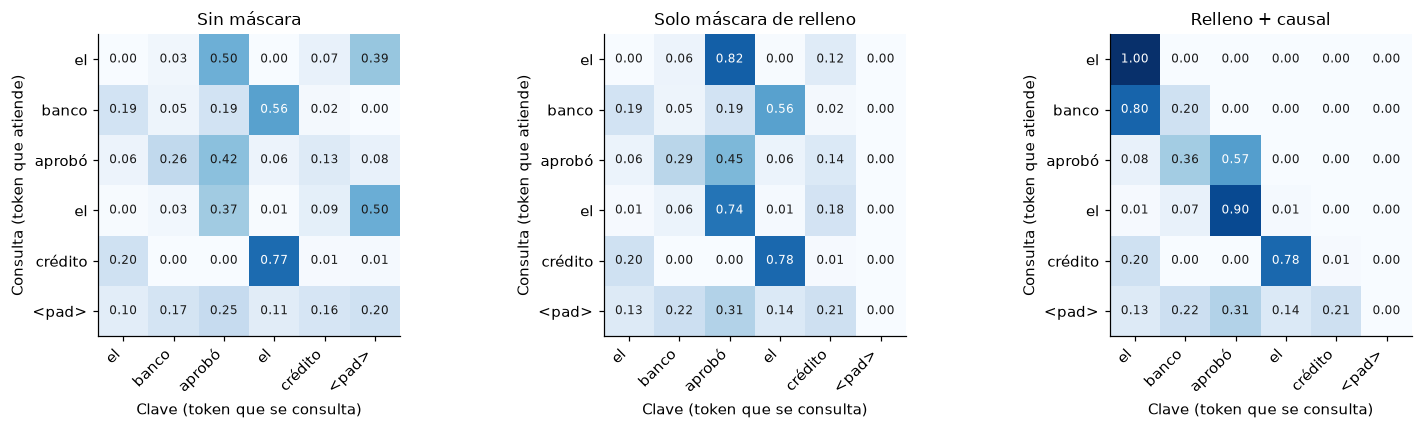

In [47]:
tokens_lote = [id_a_token[i] for i in ids_lote[0].tolist()]      # oración 1 con su <pad>

with torch.no_grad():
    _, pesos_sin = modelo(ids_lote)
    _, pesos_pad = modelo(ids_lote, mascara_relleno)
    _, pesos_causal = modelo(ids_lote, mascara_total)

fig, ejes = plt.subplots(1, 3, figsize=(14, 4))
for ax, pesos_m, titulo in zip(ejes, [pesos_sin, pesos_pad, pesos_causal],
                               ["Sin máscara", "Solo máscara de relleno", "Relleno + causal"]):
    graficar_atencion(pesos_m[0][0, 0].numpy(), tokens_lote, titulo=titulo, ax=ax)
plt.tight_layout(); plt.show()

**Lectura** (bloque 1, cabeza 1, oración 1):

- **Sin máscara:** el token `<pad>` (última columna) recibe atención de otros tokens, aunque no aporta información.
- **Solo relleno:** la columna de `<pad>` queda en 0, pero cada token todavía ve a los de su derecha.
- **Relleno + causal:** la matriz es **triangular inferior**. Cada fila reparte su atención solo entre las posiciones anteriores o iguales a ella. La primera fila ("el") solo puede atenderse a sí misma.

### Verificación: el futuro no puede influir en el pasado

Si la máscara causal funciona, cambiar el **último** token de la oración no debe alterar las representaciones de los **anteriores**. Sin máscara, en cambio, sí las altera.

In [48]:
ids_modificado = ids_lote.clone()
ids_modificado[0, 4] = token_a_id["cómodo"]       # cambiar el último token real: "crédito" -> "cómodo"

with torch.no_grad():
    sin_mascara_orig, _ = modelo(ids_lote)
    sin_mascara_mod, _ = modelo(ids_modificado)
    causal_orig, _ = modelo(ids_lote, mascara_total)
    causal_mod, _ = modelo(ids_modificado, mascara_total)

anteriores = slice(0, 4)      # posiciones 0 a 3 (los tokens previos al cambio)
print("Cambiamos el token 5 ('crédito' -> 'cómodo'). ¿Se mantienen iguales las posiciones 1 a 4?")
print("  Sin máscara causal:", torch.allclose(sin_mascara_orig[0, anteriores], sin_mascara_mod[0, anteriores], atol=1e-6))
print("  Con máscara causal:", torch.allclose(causal_orig[0, anteriores], causal_mod[0, anteriores], atol=1e-6))

Cambiamos el token 5 ('crédito' -> 'cómodo'). ¿Se mantienen iguales las posiciones 1 a 4?
  Sin máscara causal: False
  Con máscara causal: True


## 11.5 Predicción del siguiente token

Un modelo de lenguaje *decoder-only* (como GPT) se entrena con una tarea simple: **dado el texto hasta la posición $i$, predecir el token $i+1$**. Para ello se agrega una capa lineal final (la "cabeza de lenguaje") que transforma cada vector de salida $(d_{model})$ en una puntuación por cada token del vocabulario $(|V|)$, y Softmax las convierte en probabilidades:

$$
P(\text{siguiente token}\mid x_{1:i})=\operatorname{softmax}\!\big(\mathbf{h}_i\,W_{LM}\big)
$$

La máscara causal permite entrenar de forma eficiente: con **una sola pasada** se predicen **todas** las posiciones a la vez (la entrada es la secuencia sin su último token y el objetivo es la secuencia desplazada una posición).

Entrenemos un decoder **minúsculo** con nuestras dos oraciones. Es un ejemplo de juguete: el modelo solo **memoriza** esas oraciones, no comprende el idioma. Sirve para ver el mecanismo completo funcionando.

In [49]:
torch.manual_seed(1)

decoder = MiniTransformer(TAM_VOCAB, d_model=32, n_cabezas=4, d_ff=64, n_capas=2, pad_id=PAD_ID)
cabeza_lm = nn.Linear(32, TAM_VOCAB)                       # (d_model) -> puntuaciones por token del vocabulario
optimizador = torch.optim.Adam(list(decoder.parameters()) + list(cabeza_lm.parameters()), lr=3e-3)

datos = ids_lote                                           # (2, 6) con relleno
entrada, objetivo = datos[:, :-1], datos[:, 1:]            # el objetivo es la entrada desplazada una posición
n_in = entrada.size(1)
mascara_entrenamiento = (entrada != PAD_ID)[:, None, None, :] & torch.tril(torch.ones(n_in, n_in, dtype=torch.bool))

decoder.train()
for paso in range(301):
    oculto_d, _ = decoder(entrada, mascara_entrenamiento)
    logits = cabeza_lm(oculto_d)                           # (batch, n-1, |V|)
    perdida = nn.functional.cross_entropy(logits.reshape(-1, TAM_VOCAB), objetivo.reshape(-1), ignore_index=PAD_ID)
    optimizador.zero_grad(); perdida.backward(); optimizador.step()
    if paso % 100 == 0:
        print(f"paso {paso:>3} | pérdida = {perdida.item():.4f}")
_ = decoder.eval()

paso   0 | pérdida = 2.1796
paso 100 | pérdida = 0.1619
paso 200 | pérdida = 0.1568
paso 300 | pérdida = 0.1554


## 11.6 Generación autoregresiva

Para generar texto se repite un ciclo:

1. Se toma la secuencia actual (el *prompt*).
2. Se calcula la distribución de probabilidad del **siguiente** token (a partir de la **última** posición).
3. Se elige un token (aquí, el más probable: decodificación *greedy*).
4. Se **agrega** a la secuencia y se vuelve al paso 1.

Cada token generado se convierte en entrada del siguiente paso, de ahí el nombre **auto-regresivo**.

In [50]:
@torch.no_grad()
def siguiente_token(ids):
    n_ = ids.size(1)
    causal = torch.tril(torch.ones(n_, n_, dtype=torch.bool))
    oculto_g, _ = decoder(ids, causal)
    return torch.softmax(cabeza_lm(oculto_g[:, -1]), dim=-1)[0]      # distribución para la ÚLTIMA posición

@torch.no_grad()
def generar(prompt, n_nuevos):
    ids = torch.tensor([[token_a_id[t] for t in tokenizar(prompt)]])
    for _ in range(n_nuevos):
        probs = siguiente_token(ids)
        ids = torch.cat([ids, probs.argmax().view(1, 1)], dim=1)     # agregar el token más probable
    return " ".join(id_a_token[i] for i in ids[0].tolist())

print("Prompt 'el banco aprobó' ->", generar("el banco aprobó", 2))
print("Prompt 'el banco del'    ->", generar("el banco del", 3))

# Distribución de probabilidad del siguiente token tras el prompt
probs = siguiente_token(torch.tensor([[token_a_id[t] for t in tokenizar("el banco aprobó")]])).numpy()
orden = np.argsort(-probs)[:4]
pd.DataFrame({"token": [id_a_token[i] for i in orden], "probabilidad": probs[orden]})

Prompt 'el banco aprobó' -> el banco aprobó el crédito
Prompt 'el banco del'    -> el banco del parque es cómodo


,token,probabilidad
0,el,0.998
1,parque,0.000
2,cómodo,0.000
3,del,0.000


**Lectura.** Tras "el banco aprobó" el modelo asigna casi toda la probabilidad a "el" y continúa con "crédito". Tras "el banco del", continúa con "parque es cómodo". Para generar cada palabra el decoder solo pudo usar las anteriores (máscara causal), exactamente como hacen los modelos tipo GPT, pero con un vocabulario de 9 tokens y dos oraciones de entrenamiento en lugar de miles de millones de parámetros y de documentos.

> **Conexión con GPT.** Un modelo como GPT es, en esencia, esto mismo a gran escala: un decoder-only con máscara causal, entrenado para predecir el siguiente token y utilizado de forma autoregresiva. Las diferencias son de escala (datos, parámetros, capas), de tokenización (subpalabras) y de las fases de ajuste posteriores. La **elección del token** también puede ser distinta de *greedy*: muestrear según las probabilidades, con una *temperatura* que reproduce el efecto que vimos al escalar las puntuaciones en la sección 4.

# 12. Utilización de un Transformer preentrenado

**Objetivo:** observar cómo se usa un modelo real después de haber comprendido su arquitectura.

## 12.1 Modelos preentrenados y Hugging Face

Entrenar un Transformer desde cero requiere enormes cantidades de datos y cómputo. En la práctica se parte de un **modelo preentrenado**: un Transformer cuyos pesos ya fueron aprendidos sobre grandes corpus. **Hugging Face** ofrece la biblioteca `transformers` y un repositorio (el *Hub*) con miles de estos modelos.

Usaremos `bert-base-multilingual-cased`, un **encoder-only** (BERT) entrenado con textos en más de 100 idiomas, incluido el español. Es un modelo pequeño comparado con los actuales, adecuado para observar representaciones contextualizadas **sin** introducir todavía el proceso de *fine-tuning*.

> **Requisitos.** La primera ejecución descarga cerca de 700 MB desde Internet y puede tardar varios minutos. Si su entorno no tiene conexión, las celdas lo indicarán y podrá continuar con el resto del notebook, que no depende de ellas. Instalación si hace falta: `%pip install transformers`.

## 12.2 Tokenizador y configuración del modelo

In [51]:
import warnings
warnings.filterwarnings("ignore")

from transformers import AutoTokenizer, AutoModel

NOMBRE_HF = "bert-base-multilingual-cased"
HF_OK = False
try:
    tokenizador = AutoTokenizer.from_pretrained(NOMBRE_HF)
    modelo_hf = AutoModel.from_pretrained(NOMBRE_HF, output_hidden_states=True, output_attentions=True,
                                          attn_implementation="eager")
    modelo_hf.eval()
    HF_OK = True
except Exception as error:
    print("No se pudo cargar el modelo preentrenado.")
    print("Motivo:", type(error).__name__, "- compruebe su conexión a Internet. Puede omitir esta sección y la etapa 4 de la sección 13.")

if HF_OK:
    cfg = modelo_hf.config
    print("Modelo:", NOMBRE_HF)
    print(f"  d_model (hidden_size)   : {cfg.hidden_size}")
    print(f"  Bloques (num_hidden_layers) : {cfg.num_hidden_layers}")
    print(f"  Cabezas (num_attention_heads): {cfg.num_attention_heads}")
    print(f"  d_head                  : {cfg.hidden_size // cfg.num_attention_heads}")
    print(f"  d_ff (intermediate_size): {cfg.intermediate_size}")
    print(f"  Tamaño del vocabulario  : {cfg.vocab_size}")
    print(f"  Parámetros totales      : {sum(p.numel() for p in modelo_hf.parameters()):,}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Modelo: bert-base-multilingual-cased
  d_model (hidden_size)   : 768
  Bloques (num_hidden_layers) : 12
  Cabezas (num_attention_heads): 12
  d_head                  : 64
  d_ff (intermediate_size): 3072
  Tamaño del vocabulario  : 119547
  Parámetros totales      : 177,853,440


Compare con lo que construimos: `d_model`, número de bloques, cabezas, `d_ff = 4 x d_model`. Es **la misma arquitectura** de las secciones 7 a 10, con otras dimensiones.

## 12.3 y 12.4 Tokenización y procesamiento de una secuencia

El tokenizador de BERT usa **WordPiece**: divide las palabras en subpalabras (las que empiezan con `##` continúan la palabra anterior) y añade tokens especiales: `[CLS]` al inicio y `[SEP]` al final.

In [52]:
oraciones_hf = {
    "A (finanzas)":   "El banco aprobó el crédito.",
    "B (mobiliario)": "El banco del parque es cómodo.",
    "C (finanzas)":   "El banco rechazó la solicitud de préstamo.",
}

if HF_OK:
    for nombre, texto in oraciones_hf.items():
        codificado = tokenizador(texto, return_tensors="pt")
        print(f"{nombre}: {texto}")
        print("   tokens   :", tokenizador.convert_ids_to_tokens(codificado["input_ids"][0]))
        print("   input_ids:", codificado["input_ids"][0].tolist())
    print("\nattention_mask (1 = token real, 0 = relleno):", codificado["attention_mask"][0].tolist())
else:
    print("Celda omitida: el modelo no está disponible.")

A (finanzas): El banco aprobó el crédito.
   tokens   : ['[CLS]', 'El', 'banco', 'ap', '##robó', 'el', 'c', '##rédito', '.', '[SEP]']
   input_ids: [101, 10224, 55379, 26219, 110365, 10125, 171, 86161, 119, 102]
B (mobiliario): El banco del parque es cómodo.
   tokens   : ['[CLS]', 'El', 'banco', 'del', 'parque', 'es', 'cómo', '##do', '.', '[SEP]']
   input_ids: [101, 10224, 55379, 10127, 29562, 10196, 39649, 10317, 119, 102]
C (finanzas): El banco rechazó la solicitud de préstamo.
   tokens   : ['[CLS]', 'El', 'banco', 're', '##cha', '##zó', 'la', 'soli', '##citu', '##d', 'de', 'pré', '##sta', '##mo', '.', '[SEP]']
   input_ids: [101, 10224, 55379, 11639, 12964, 16993, 10109, 36766, 108272, 10162, 10104, 42621, 10972, 11033, 119, 102]

attention_mask (1 = token real, 0 = relleno): [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


## 12.5 y 12.6 Representaciones contextualizadas y dimensiones

El modelo devuelve:

- `last_hidden_state`: la salida del último bloque, forma `(batch, seq_len, d_model)`.
- `hidden_states`: una **tupla con la salida de cada capa**: el índice 0 son los embeddings de entrada (token + posición + tipo de segmento, ya normalizados) y los siguientes, los bloques 1, 2, ..., N.
- `attentions`: los pesos de atención de cada bloque, forma `(batch, heads, seq_len, seq_len)`.

In [53]:
def representar(texto):
    """Devuelve (tokens, hidden_states, attentions) del modelo preentrenado para un texto."""
    codificado = tokenizador(texto, return_tensors="pt")
    with torch.no_grad():
        salida = modelo_hf(**codificado)
    tokens = tokenizador.convert_ids_to_tokens(codificado["input_ids"][0])
    return tokens, salida.hidden_states, salida.attentions

if HF_OK:
    tokens_a, hs_a, att_a = representar(oraciones_hf["A (finanzas)"])
    print("last_hidden_state :", tuple(hs_a[-1].shape), "-> (batch, seq_len, d_model)")
    print("hidden_states     :", len(hs_a), "tensores (embeddings + una salida por cada bloque)")
    print("attentions        :", len(att_a), "tensores de forma", tuple(att_a[0].shape), "-> (batch, heads, seq_len, seq_len)")
else:
    print("Celda omitida: el modelo no está disponible.")

last_hidden_state : (1, 10, 768) -> (batch, seq_len, d_model)
hidden_states     : 13 tensores (embeddings + una salida por cada bloque)
attentions        : 12 tensores de forma (1, 12, 10, 10) -> (batch, heads, seq_len, seq_len)


## 12.7 Comparación de representaciones para distintos contextos

Medimos cómo cambia la representación de **"banco"** entre las oraciones. Como "banco" puede estar dividido en varias subpalabras, promediamos sus vectores. Para cada capa calculamos la similitud coseno entre:

- **A y B:** "banco" financiero frente a "banco" del parque, es decir, un asiento (sentidos distintos).
- **A y C:** "banco" financiero frente a "banco" financiero en otra oración (mismo sentido).

**Antes de ejecutar, anticipe:** en la capa 0 (embeddings de entrada, antes de cualquier atención), ¿cuál será la similitud, teniendo en cuenta que "banco" ocupa la misma posición en las tres oraciones? ¿Qué espera que ocurra en las capas superiores?

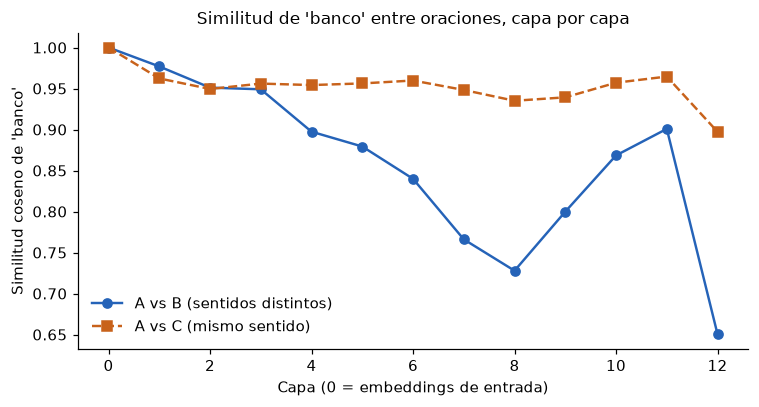

Capa 0   : A-B = 1.000 | A-C = 1.000
Capa 12  : A-B = 0.650 | A-C = 0.897


In [54]:
def vector_de(texto, palabra, capa):
    """Vector de una palabra (promedio de sus subpalabras) en la capa indicada."""
    tokens, hs, _ = representar(texto)
    sub = tokenizador.tokenize(palabra)
    for i in range(len(tokens) - len(sub) + 1):
        if tokens[i:i + len(sub)] == sub:
            return hs[capa][0, i:i + len(sub)].mean(dim=0).numpy()
    raise ValueError(f"'{palabra}' no aparece en {tokens}")

if HF_OK:
    n_capas = modelo_hf.config.num_hidden_layers
    sim_AB, sim_AC = [], []
    for capa in range(n_capas + 1):
        vA = vector_de(oraciones_hf["A (finanzas)"], "banco", capa)
        vB = vector_de(oraciones_hf["B (mobiliario)"], "banco", capa)
        vC = vector_de(oraciones_hf["C (finanzas)"], "banco", capa)
        sim_AB.append(coseno(vA, vB)); sim_AC.append(coseno(vA, vC))
    cos_hf_ultima, cos_hf_ac = sim_AB[-1], sim_AC[-1]

    fig, ax = plt.subplots(figsize=(7, 3.8))
    ax.plot(sim_AB, "-", marker="o", color=AZUL, lw=1.6, label="A vs B (sentidos distintos)")
    ax.plot(sim_AC, "--", marker="s", color=NARANJA, lw=1.6, label="A vs C (mismo sentido)")
    ax.set_xlabel("Capa (0 = embeddings de entrada)"); ax.set_ylabel("Similitud coseno de 'banco'")
    ax.set_title("Similitud de 'banco' entre oraciones, capa por capa")
    ax.set_xticks(range(0, n_capas + 1, 2)); ax.legend(frameon=False)
    plt.tight_layout(); plt.show()

    print(f"Capa 0   : A-B = {sim_AB[0]:.3f} | A-C = {sim_AC[0]:.3f}")
    print(f"Capa {n_capas:>2}  : A-B = {sim_AB[-1]:.3f} | A-C = {sim_AC[-1]:.3f}")
else:
    print("Celda omitida: el modelo no está disponible.")

**Cómo leer el resultado.** En la capa 0 todavía no ha actuado la atención, pero esa capa **no es un embedding puramente estático**: BERT ya sumó al vector del token un embedding de posición. Aquí la similitud debe ser 1 porque "banco" ocupa **la misma posición** en las tres oraciones (después de `[CLS]` y "El"). Si mueve la palabra a otra posición, dejará de ser 1 aunque no haya contexto de por medio. En las capas superiores, la representación de "banco" deja de ser idéntica entre oraciones porque ya incorporó información de las palabras vecinas. Compare las dos curvas y contraste con su predicción: si el modelo distingue los sentidos, la curva A-C (mismo sentido) debería quedar por encima de A-B (sentidos distintos), aunque la diferencia exacta depende del modelo y no está garantizada. Con tres oraciones no se puede generalizar; para concluir algo firme habría que probar muchas palabras y muchas oraciones, como se hizo en la evaluación del tema anterior.

### Mapa de atención de un modelo real

Visualicemos los pesos de atención de una cabeza concreta con la misma función de la sección 6. Cambie `capa` y `cabeza` para explorar. En BERT es habitual que muchas cabezas dirijan buena parte de su atención a los tokens especiales `[CLS]` y `[SEP]`; recuerde la advertencia de la sección 6 sobre la interpretación.

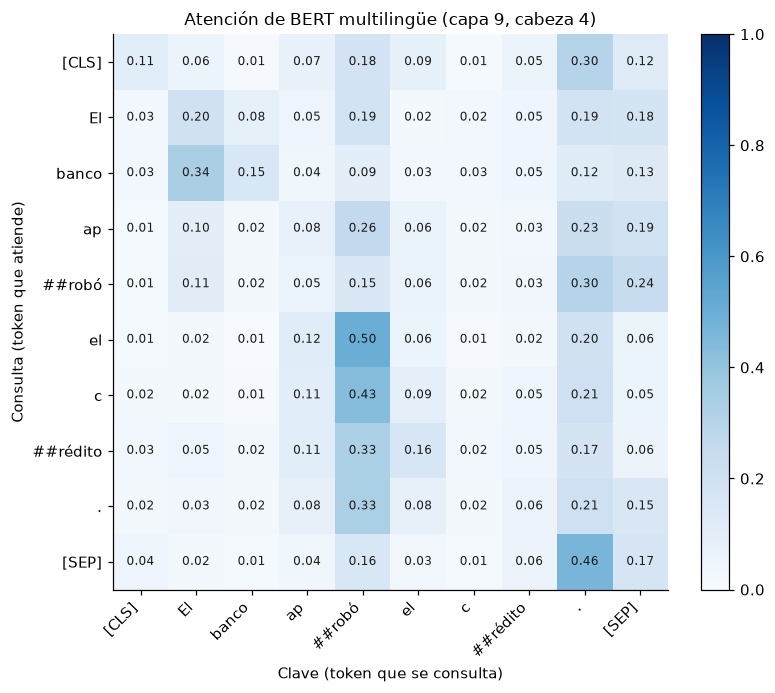

In [55]:
if HF_OK:
    capa, cabeza = 8, 3         # <- modifique estos valores (capa: 0 a 11; cabeza: 0 a 11)
    tokens_a, _, att_a = representar(oraciones_hf["A (finanzas)"])
    graficar_atencion(att_a[capa][0, cabeza].numpy(), tokens_a,
                      titulo=f"Atención de BERT multilingüe (capa {capa + 1}, cabeza {cabeza + 1})")
else:
    print("Celda omitida: el modelo no está disponible.")

### Conexión con el tema anterior (opcional)

Los modelos de `sentence-transformers` del notebook de embeddings son **encoders**: un Transformer como el que acabamos de usar, entrenado para que oraciones con significado parecido tengan vectores cercanos y con un paso final que **promedia** los vectores de los tokens (*mean pooling*) para obtener un único vector por oración. Contrastemos la similitud entre nuestras tres oraciones.

In [56]:
try:
    from sentence_transformers import SentenceTransformer
    st_modelo = SentenceTransformer("sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2")
    textos = list(oraciones_hf.values())
    emb_st = st_modelo.encode(textos, normalize_embeddings=True)
    sim_st = emb_st @ emb_st.T
    display(pd.DataFrame(sim_st, index=list(oraciones_hf), columns=list(oraciones_hf)).round(3))
except Exception as error:
    print("Celda opcional omitida:", type(error).__name__, "(falta la biblioteca o la conexión).")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

,A (finanzas),B (mobiliario),C (finanzas)
A (finanzas),1.000,-0.001,0.370
B (mobiliario),-0.001,1.000,-0.051
C (finanzas),0.370,-0.051,1.000


# 13. Comparación y análisis de resultados

**Objetivo:** consolidar el aprendizaje mediante una comparación experimental válida.

Hacemos dos comparaciones **por separado**, porque usan vectores de naturaleza distinta y sus valores no se pueden comparar entre sí:

| Comparación | Qué se compara | Pregunta |
|---|---|---|
| A. Ejemplo de juguete | "banco" en las oraciones 1 y 2, antes y después de Self-Attention (sección 6) | ¿La atención hace que el vector dependa del contexto? |
| B. Modelo preentrenado | "banco" en la última capa de BERT: A-B (sentidos distintos) y A-C (mismo sentido) | ¿El modelo acerca los usos con el mismo sentido? |

La métrica es la **similitud coseno**. En la comparación A, un valor menor que 1 solo indica que el vector **cambió**. Un coseno bajo por sí solo no demuestra que el modelo distinga sentidos: para eso hace falta la comparación B, con un par de control del mismo sentido.

> **Por qué no se incluye Multi-Head.** Con los pesos aleatorios de la sección 7, este coseno depende casi por completo de la semilla: en 200 semillas varió de −0.72 a 1.00. Ese valor no mide nada del contexto.

In [57]:
# Comparación A: ejemplo de juguete (sección 6)
display(pd.DataFrame({
    "etapa": ["Embeddings iniciales", "Después de Self-Attention"],
    "coseno de 'banco' entre las oraciones 1 y 2": [coseno(banco_en_1, banco_en_2), coseno(banco_ctx_1, banco_ctx_2)],
}))

# Comparación B: modelo preentrenado (sección 12, si se cargó)
if "cos_hf_ultima" in globals():
    display(pd.DataFrame({
        "par de oraciones": ["A-B (sentidos distintos)", "A-C (mismo sentido)"],
        "coseno de 'banco' en la última capa de BERT": [cos_hf_ultima, cos_hf_ac],
    }))
else:
    print("Nota: la comparación B no aparece porque el modelo preentrenado no se cargó en la sección 12.")

,etapa,coseno de 'banco' entre las oraciones 1 y 2
0,Embeddings iniciales,1.000
1,Después de Self-Attention,0.926


,par de oraciones,coseno de 'banco' en la última capa de BERT
0,A-B (sentidos distintos),0.650
1,A-C (mismo sentido),0.897


**Interpretación.**

- **Comparación A:** la similitud baja de 1 a menos de 1 porque cada oración aporta un contexto distinto a la mezcla. Esto muestra que el vector cambió, y el resultado depende de un léxico diseñado a mano.
- **Comparación B:** si A-C queda por encima de A-B, hay un indicio de que el modelo acerca los usos con el mismo sentido. Si no ocurre, regístrelo tal como salió: no está garantizado.

**Aviso metodológico.** Los valores de A y B no son comparables en magnitud, y tres oraciones no bastan para generalizar. Esta tabla ilustra el mecanismo; no mide la calidad de un modelo.

## Preguntas de análisis

Responda cada pregunta con sus propias palabras, apoyándose en los experimentos de este notebook.

1. ¿Por qué una representación contextualizada puede ser más útil que un embedding estático?
2. ¿Qué aporta Multi-Head Attention frente a una sola cabeza?
3. ¿Qué problema resuelve la codificación posicional?
4. ¿Por qué un Transformer necesita varias capas (bloques)?
5. ¿Qué diferencias existen entre un encoder y un decoder?
6. ¿Qué limitaciones presenta la atención?

In [58]:
# Escriba aquí sus respuestas como comentarios o en una celda de texto nueva.

### Respuestas orientativas (para el docente: elimine esta celda antes de entregar el notebook a los estudiantes)

1. **Contextualizada frente a estática.** Un vector estático asigna a una palabra siempre la misma representación, por lo que no resuelve la ambigüedad ("banco" financiero frente a "banco" del parque). La contextual ajusta el vector según las palabras vecinas, de modo que tareas como búsqueda, clasificación o desambiguación reciben una representación acorde con el significado en uso. Lo vimos en la sección 6 (el coseno entre los dos "banco" pasó de 1 a menos de 1).
2. **Multi-Head.** Permite varios patrones de atención en paralelo, cada uno en un subespacio propio; así el modelo puede capturar distintos tipos de relación a la vez, sin aumentar el número de parámetros respecto de una cabeza de ancho completo. No todas las cabezas se especializan, y algunas son redundantes.
3. **Codificación posicional.** La atención por sí sola no distingue el orden (sección 8: "perro muerde hombre" y "hombre muerde perro" daban las mismas salidas por token). La codificación posicional inyecta la posición en los embeddings.
4. **Varias capas.** Cada bloque recibe representaciones ya contextualizadas y puede combinarlas de nuevas formas. La profundidad permite refinar progresivamente la representación y modelar relaciones indirectas o de mayor nivel.
5. **Encoder frente a decoder.** El encoder usa atención bidireccional (cada token ve a todos) y se emplea para comprender y representar; el decoder usa atención causal (solo ve el pasado) y genera token a token; el decoder del Transformer original añade cross-attention hacia el encoder.
6. **Limitaciones.** El costo crece de forma cuadrática con la longitud de la secuencia ($n\times n$); hay un límite de contexto; la atención no garantiza comprensión ni constituye una explicación completa de las decisiones del modelo; y las representaciones heredan los sesgos y la cobertura de los datos de entrenamiento.

# 14. Actividad integradora

## Título: construcción y análisis de un mecanismo de atención

**Escenario.** Debe construir, **por su cuenta**, un mecanismo de atención completo sobre una secuencia propia, desde los embeddings hasta Multi-Head, y analizar los resultados. Puede reutilizar las funciones definidas en este notebook: `tokenizar`, `softmax`, `coseno`, `self_attention`, `atencion_multicabeza`, `graficar_atencion` y `codificacion_posicional`.

## Pasos

| N.º | Tarea | Sugerencia |
|---|---|---|
| 1 | Crear una secuencia de entrada (una oración de 5 a 8 palabras) | Que contenga una palabra ambigua o un pronombre |
| 2 | Generar sus embeddings | Cree su propio léxico de vectores **diseñados a mano**, con dimensiones que tengan sentido para su oración. Con embeddings aleatorios no habría relaciones que interpretar |
| 3 | Construir las matrices $Q$, $K$ y $V$ | Use $W_Q=W_K=W_V=I$ para los mapas que va a interpretar (como en la sección 6) |
| 4 | Calcular las puntuaciones de atención | $QK^\top/\sqrt{d_k}$ |
| 5 | Aplicar Softmax | Verifique que cada fila suma 1 |
| 6 | Construir la representación contextualizada | pesos @ $V$ |
| 7 | Implementar Multi-Head Attention | Al menos 2 cabezas. Con pesos aleatorios, compruebe las formas y que los mapas difieren, sin atribuirles significado |
| 8 | Visualizar los resultados | Mapas de calor de cada cabeza |
| 9 | Explicar qué relaciones se identifican y qué limitaciones existen | Interprete solo mapas del léxico diseñado o de un modelo preentrenado. Recuerde la advertencia de la sección 6 |

## Entregable

1. Este notebook **ejecutado**, con sus visualizaciones.
2. Un **breve informe técnico** (1 a 2 páginas) que incluya: la secuencia elegida, una explicación del flujo $X\to Q,K,V\to$ puntuaciones $\to$ Softmax $\to$ salida, las gráficas y su interpretación, y una discusión honesta de las limitaciones (vectores diseñados a mano, pesos sin entrenar, atención como no explicación, tamaño del ejemplo).

## Criterios de evaluación

| Criterio | Peso |
|---|---|
| Corrección de la implementación (formas, Softmax, Multi-Head) | 30 % |
| Visualizaciones claras y bien rotuladas | 20 % |
| Interpretación de las relaciones identificadas en mapas con léxico diseñado o modelo preentrenado | 20 % |
| Análisis crítico de limitaciones | 20 % |
| Claridad y reproducibilidad (semillas, celdas ejecutables en orden) | 10 % |

In [59]:
# Paso 1-2. Secuencia y embeddings

In [60]:
# Paso 3-6. Q, K, V, puntuaciones, Softmax y representación contextualizada

In [61]:
# Paso 7-8. Multi-Head Attention y visualización

In [62]:
# Paso 9. Escriba su análisis como comentarios, o en una celda de texto nueva.

# 15. Cierre y conexión con el siguiente tema

## Qué aprendimos

1. Un **embedding estático** da el mismo vector a una palabra en todos los contextos; una **representación contextual** lo ajusta a cada oración.
2. La **atención** calcula, para cada token, una **mezcla ponderada** de la información de los demás: producto punto $\to$ Softmax $\to$ suma ponderada.
3. **Self-Attention** separa tres papeles con proyecciones aprendibles: $Q=XW_Q$, $K=XW_K$, $V=XW_V$, y $\operatorname{Attention}(Q,K,V)=\operatorname{softmax}(QK^\top/\sqrt{d_k})V$. El factor $\sqrt{d_k}$ evita que Softmax se sature al crecer la dimensión.
4. **Multi-Head Attention** ejecuta varias atenciones en paralelo en subespacios distintos y combina sus resultados con $W_O$.
5. La atención no conoce el orden: la **codificación posicional** lo aporta.
6. Un **bloque Transformer** combina Multi-Head Attention, Add & Norm, FFN y Add & Norm; se apila $N$ veces. Las **máscaras** (de relleno y causal) controlan qué posiciones puede ver cada token.
7. Existen tres familias: **encoder-only** (BERT), **decoder-only** (GPT) y **encoder-decoder** (T5).
8. Los pesos de atención son un **patrón observable**, no una explicación completa.

## Pregunta que abre el siguiente tema

> Si ya comprendemos cómo funciona un Transformer y cómo procesa información, ¿cómo podemos **adaptar un modelo preentrenado a una tarea específica** y comprobar si **realmente mejora** su desempeño?

## Tres etapas del ciclo de vida de un modelo (adelanto)

| Etapa | Qué ocurre | Datos | Resultado |
|---|---|---|---|
| **Preentrenamiento** | El modelo aprende representaciones generales del lenguaje | Corpus enormes, sin etiquetas específicas de la tarea | Un modelo base (como el BERT de la sección 12) |
| **Fine-tuning** | Se ajustan los pesos con datos de una tarea concreta | Conjunto etiquetado, mucho más pequeño | Un modelo especializado |
| **Inferencia** | Se usa el modelo ya entrenado para producir resultados | Datos nuevos | Predicciones o texto generado (como la generación de la sección 11) |

El **siguiente tema**, *Fine-tuning y evaluación de modelos de lenguaje*, desarrollará cómo adaptar un modelo y, sobre todo, **cómo evaluar con rigor si la adaptación funcionó**, retomando las ideas de evaluación del notebook de embeddings.

## Referencias

- Vaswani, A. et al. (2017). *Attention Is All You Need*. Advances in Neural Information Processing Systems 30.
- Devlin, J. et al. (2019). *BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding*. NAACL.
- Clark, K. et al. (2019). *What Does BERT Look At? An Analysis of BERT's Attention*. BlackboxNLP.
- Jain, S. y Wallace, B. (2019). *Attention is not Explanation*. NAACL. / Wiegreffe, S. y Pinter, Y. (2019). *Attention is not not Explanation*. EMNLP.
- Alammar, J. *The Illustrated Transformer* (recurso divulgativo con diagramas).
- Documentación de PyTorch (`torch.nn`) y de Hugging Face Transformers.